<a href="https://colab.research.google.com/github/pikey-msc/RiesgosFinancieros/blob/master/2027-1/Merton_KMV_mercado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Merton y KMV con datos de mercado
**Del precio de la acción a la distancia al default (DD), la EDF y el riesgo de una cartera.**
Versión ampliada del notebook `Merton_KMV_py.ipynb`, siguiendo el capítulo 3 de los apuntes (§2.2.5 Merton y KMV).

**Notación del curso** (distinta a la de la literatura: V, E, F):
$K_t$ = valor de los **activos**, $A_t$ = valor del **capital** (acciones), $D$ = valor nominal de la deuda, $\sigma_K$ = vol. de activos, $\sigma_A$ = vol. del capital.

| Sección | Contenido |
|---|---|
| — | **Mapa conceptual Merton vs KMV** (diagrama: quién depende de quién) |
| 0 | Motor: Merton, sistema 2×2 (Newton), KMV iterativo, MLE de Duan, barrera, saltos, Vasicek |
| 1 | Merton directo: el capital es una *call*; PD, LGD endógena, spread |
| 2 | **Datos de mercado** (yfinance; si no hay red usa el *snapshot* de tu notebook) |
| 3 | Calibración $(K_0,\sigma_K)$ y sensibilidad al punto de default |
| 3b | **Merton a fondo con WALMEX:** teoría, identidades verificadas, distancia al default en unidades históricas, colas, ejercicios resueltos |
| 4 | Estimación con la serie de tiempo: KMV iterativo vs MLE vs ingenuo; DD(t) |
| 5 | Extensiones: Black–Cox (barrera), saltos de Merton, estructura temporal de PD y spread |
| 6 | Del DD a la EDF **empírica** (base de datos simulada con colas pesadas) |
| 7 | Cartera: correlaciones de activos, Gaussian copula vs Vasicek, VaR |
| 8 | Ejercicios para el alumno |
| 9 | Errores del notebook original y referencias |

> **Modo de datos.** La celda 2.1 intenta descargar con `yfinance`. Si no hay red (o falla), usa un *snapshot* con las cifras de tu notebook (WALMEX, dic-2021 / jun-2022) y una serie de precios **simulada**; el notebook lo avisa con `MODO = 'OFFLINE'`.

## Mapa conceptual: Merton vs KMV
**Merton** va de las causas (activos) al riesgo (valuación, PD, LGD, spread); **KMV** va del precio observado (capital) a las causas ($K_0,\sigma_K$) y de ahí a la DD y la EDF empírica. Cada uno necesita al otro: Merton necesita $K_0,\sigma_K$; KMV necesita la fórmula de Merton (la call) para despejarlos.

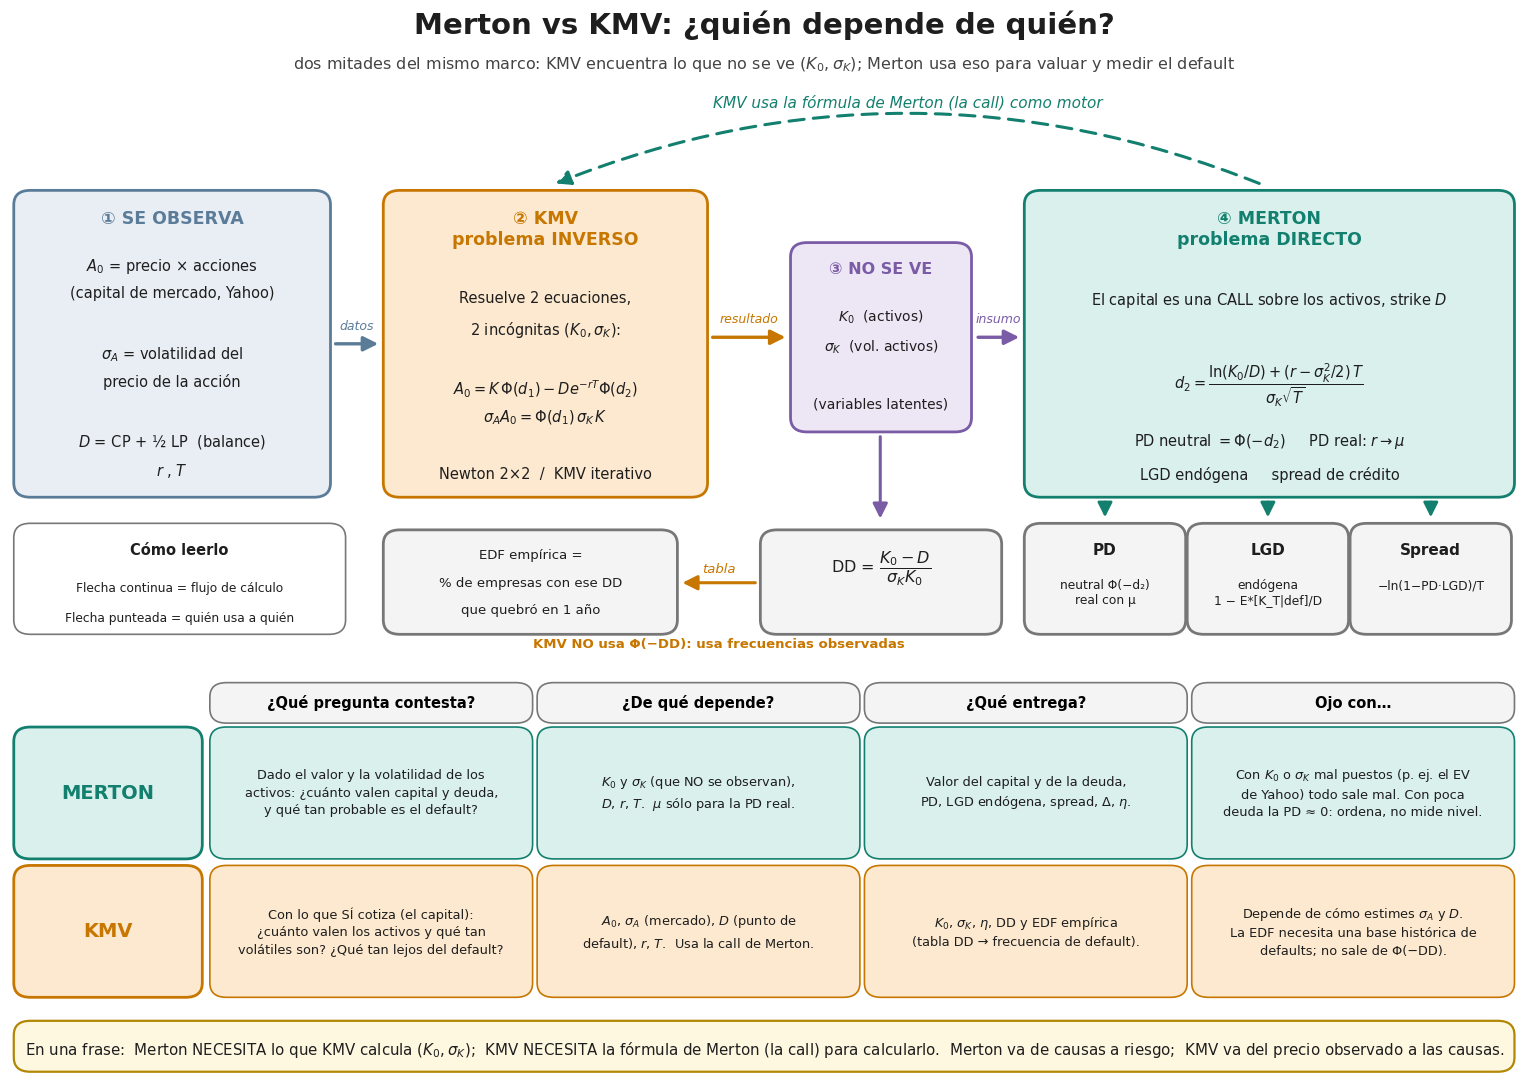

In [1]:
# Mapa conceptual: Merton vs KMV — ¿quién depende de quién? (autocontenida: sólo matplotlib)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
C = dict(obs='#E8EEF4', obs_e='#5B7C99', kmv='#FCE9CF', kmv_e='#C77700', lat='#EDE6F5', lat_e='#7A5BA6', mer='#D9F0EC', mer_e='#13806F', out='#F4F4F4', out_e='#777777', ink='#1E1E1E')
fig, ax = plt.subplots(figsize=(17, 11)); ax.set_xlim(0, 100); ax.set_ylim(-4.5, 77); ax.axis('off')

def box(x0, y0, x1, y1, fc, ec, title=None, lines=(), fs=10.5, tfs=12.5, lw=2, ty=None, ls=None):
    ax.add_patch(FancyBboxPatch((x0, y0), x1 - x0, y1 - y0, boxstyle='round,pad=0.25,rounding_size=1.1', fc=fc, ec=ec, lw=lw))
    y = y1 - 1.2
    if title: ax.text((x0 + x1)/2, y, title, ha='center', va='top', fontsize=tfs, fontweight='bold', color=ec if ec != C['out_e'] else C['ink']); y -= (ty or 3.6)
    for ln in lines:
        ax.text((x0 + x1)/2, y, ln, ha='center', va='top', fontsize=fs, color=C['ink']); y -= (ls or 2.25)
def arrow(p, q, color, txt=None, rad=0, ls='-', lw=2.4, tpos=None, fs=9.5, tcolor=None):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=22, color=color, lw=lw, linestyle=ls, connectionstyle=f'arc3,rad={rad}', shrinkA=2, shrinkB=2))
    if txt: ax.text(*(tpos or ((p[0] + q[0])/2, (p[1] + q[1])/2 + 1.2)), txt, ha='center', va='bottom', fontsize=fs, color=tcolor or color, style='italic')

ax.text(50, 75.3, 'Merton vs KMV: ¿quién depende de quién?', ha='center', fontsize=21, fontweight='bold', color=C['ink'])
ax.text(50, 72.6, 'dos mitades del mismo marco: KMV encuentra lo que no se ve ($K_0,\\sigma_K$); Merton usa eso para valuar y medir el default', ha='center', fontsize=11.5, color='#444')

# ---- fila superior: flujo ----
box(0.5, 40, 21, 63, C['obs'], C['obs_e'], '① SE OBSERVA', ['$A_0$ = precio × acciones', '(capital de mercado, Yahoo)', '', '$\\sigma_A$ = volatilidad del', 'precio de la acción', '', '$D$ = CP + ½ LP  (balance)', '$r$ , $T$'], fs=10.5)
box(25, 40, 46, 63, C['kmv'], C['kmv_e'], '② KMV\nproblema INVERSO', ['Resuelve 2 ecuaciones,', '2 incógnitas $(K_0,\\sigma_K)$:', '', '$A_0=K\\,\\Phi(d_1)-De^{-rT}\\Phi(d_2)$', '$\\sigma_A A_0=\\Phi(d_1)\\,\\sigma_K\\,K$', '', 'Newton 2×2  /  KMV iterativo'], fs=10.5, ty=6.2)
box(52, 45, 63.5, 59, C['lat'], C['lat_e'], '③ NO SE VE', ['$K_0$  (activos)', '$\\sigma_K$  (vol. activos)', '', '(variables latentes)'], fs=10, tfs=11.5)
box(67.5, 40, 99.5, 63, C['mer'], C['mer_e'], '④ MERTON\nproblema DIRECTO', ['El capital es una CALL sobre los activos, strike $D$', '', '$d_2=\\dfrac{\\ln(K_0/D)+(r-\\sigma_K^2/2)\\,T}{\\sigma_K\\sqrt{T}}$', '', 'PD neutral $=\\Phi(-d_2)$     PD real: $r\\to\\mu$', 'LGD endógena     spread de crédito'], fs=10.5, ty=6.2, ls=2.7)
arrow((21.4, 51.5), (24.6, 51.5), C['obs_e'], 'datos', tpos=(23, 52.4), fs=9)
arrow((46.4, 52), (51.6, 52), C['kmv_e'], 'resultado', tpos=(49, 52.9), fs=9)
arrow((64, 52), (67.1, 52), C['lat_e'], 'insumo', tpos=(65.5, 52.9), fs=9)
# KMV usa la call de Merton como motor (flecha punteada por arriba)
arrow((83, 63.7), (36, 63.7), C['mer_e'], 'KMV usa la fórmula de Merton (la call) como motor', rad=0.2, ls=(0, (5, 3)), tpos=(59.5, 69.4), fs=11, lw=2.2)

# ---- fila media: salidas ----
box(50, 29.5, 65.5, 37, C['out'], C['out_e'], None, ['DD = $\\dfrac{K_0-D}{\\sigma_K K_0}$'], fs=11.5, ls=2)
box(25, 29.5, 44, 37, C['out'], C['out_e'], None, ['EDF empírica =', '% de empresas con ese DD', 'que quebró en 1 año'], fs=9.5, ls=2.1)
arrow((57.7, 44.6), (57.7, 37.9), C['lat_e'], lw=2.2)
arrow((49.6, 33.2), (44.4, 33.2), C['kmv_e'], lw=2.2)
ax.text(47, 34.0, 'tabla', ha='center', fontsize=9.5, color=C['kmv_e'], style='italic')
ax.text(47, 29.0, 'KMV NO usa Φ(−DD): usa frecuencias observadas', ha='center', va='top', fontsize=9.5, color=C['kmv_e'], fontweight='bold')
box(0.5, 29.5, 22, 37.5, '#FFFFFF', C['out_e'], 'Cómo leerlo', ['Flecha continua = flujo de cálculo', 'Flecha punteada = quién usa a quién'], fs=8.8, tfs=10.5, ty=3.0, ls=2.3, lw=1.2)
for i, (t, sub) in enumerate((('PD', 'neutral Φ(−d₂)\nreal con μ'), ('LGD', 'endógena\n1 − E*[K_T|def]/D'), ('Spread', '−ln(1−PD·LGD)/T'))):
    x0 = 67.5 + i*10.8; box(x0, 29.5, x0 + 10.2, 37.5, C['out'], C['out_e'], t, [sub], fs=8.8, tfs=11, ty=2.8, ls=2.1)
    arrow((x0 + 5.1, 39.6), (x0 + 5.1, 38.0), C['mer_e'], lw=2)

# ---- tabla comparativa ----
cols = ['¿Qué pregunta contesta?', '¿De qué depende?', '¿Qué entrega?', 'Ojo con…']; w = 20.9; xs = [13.5 + i*(w + .8) for i in range(4)]
rows = (('MERTON', C['mer'], C['mer_e'],
         ['Dado el valor y la volatilidad de los\nactivos: ¿cuánto valen capital y deuda,\ny qué tan probable es el default?',
          '$K_0$ y $\\sigma_K$ (que NO se observan),\n$D$, $r$, $T$.  $\\mu$ sólo para la PD real.',
          'Valor del capital y de la deuda,\nPD, LGD endógena, spread, $\\Delta$, $\\eta$.',
          'Con $K_0$ o $\\sigma_K$ mal puestos (p. ej. el EV\nde Yahoo) todo sale mal. Con poca\ndeuda la PD ≈ 0: ordena, no mide nivel.']),
        ('KMV', C['kmv'], C['kmv_e'],
         ['Con lo que SÍ cotiza (el capital):\n¿cuánto valen los activos y qué tan\nvolátiles son? ¿Qué tan lejos del default?',
          '$A_0$, $\\sigma_A$ (mercado), $D$ (punto de\ndefault), $r$, $T$.  Usa la call de Merton.',
          '$K_0$, $\\sigma_K$, $\\eta$, DD y EDF empírica\n(tabla DD → frecuencia de default).',
          'Depende de cómo estimes $\\sigma_A$ y $D$.\nLa EDF necesita una base histórica de\ndefaults; no sale de Φ(−DD).']))
y_top = 25.3
for j, (c, x) in enumerate(zip(cols, xs)): box(x, y_top - 2.6, x + w, y_top, C['out'], C['out_e'], None, [], lw=1.2); ax.text(x + w/2, y_top - 1.3, c, ha='center', va='center', fontsize=10.5, fontweight='bold')
for k, (nm, fc, ec, cells) in enumerate(rows):
    y1 = y_top - 3.4 - k*10.6; y0 = y1 - 9.6
    box(0.5, y0, 12.5, y1, fc, ec, None, [], lw=2); ax.text(6.5, (y0 + y1)/2, nm, ha='center', va='center', fontsize=14, fontweight='bold', color=ec)
    for x, t in zip(xs, cells): box(x, y0, x + w, y1, fc, ec, None, [], lw=1.2); ax.text(x + w/2, (y0 + y1)/2, t, ha='center', va='center', fontsize=9.3, color=C['ink'], linespacing=1.45)
box(0.5, -4, 99.5, -0.6, '#FFF8E1', '#B28704', None, ['En una frase:  Merton NECESITA lo que KMV calcula ($K_0,\\sigma_K$);  KMV NECESITA la fórmula de Merton (la call) para calcularlo.  Merton va de causas a riesgo;  KMV va del precio observado a las causas.'], fs=10.8, lw=1.6, ls=2)
plt.tight_layout(); plt.savefig('merton_vs_kmv.png', dpi=150, bbox_inches='tight'); plt.show()      # también queda guardado como PNG

In [2]:
# 0. Motor ---------------------------------------------------------------
import warnings, logging; warnings.filterwarnings('ignore'); logging.getLogger('yfinance').setLevel(logging.CRITICAL)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.special import gammaln
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})
N, n_ = norm.cdf, norm.pdf
H = 1/252                                              # paso diario

def d12(K, D, r, s, T):
    d1 = (np.log(K/D) + (r + .5*s*s)*T)/(s*np.sqrt(T)); return d1, d1 - s*np.sqrt(T)

def call(K, D, r, s, T):                                # capital A = call sobre K con strike D (vectorizada)
    d1, d2 = d12(K, D, r, s, T); return K*N(d1) - D*np.exp(-r*T)*N(d2)

def merton(K0, D, r, s, T, mu=None):
    """Valuación de Merton. PD neutral = Φ(-d2); PD real usa μ; LGD endógena = 1 - E*[K_T|default]/D.
    D0 y spread se calculan con fórmulas cerradas (no como K0 − A0, que se anula por redondeo si D≪K0)."""
    d1, d2 = d12(K0, D, r, s, T); A = call(K0, D, r, s, T); mu = r if mu is None else mu
    pdq = N(-d2); pdp = N(-(np.log(K0/D) + (mu - .5*s*s)*T)/(s*np.sqrt(T))); ek = K0*np.exp(r*T)*N(-d1)/D          # ek = E*[K_T 1{K_T≤D}]/D
    Dm = D*np.exp(-r*T)*N(d2) + K0*N(-d1); EL = pdq - ek                                                          # EL = PD·LGD (pérdida esperada neutral)
    return dict(d1=d1, d2=d2, A=A, Dm=Dm, pdq=pdq, pdp=pdp, lgd=1 - ek/pdq if pdq > 1e-300 else np.nan, spread=-np.log1p(-EL)/T,
                delta=N(d1), eta=K0*N(d1)/A)

def bis(f, lo, hi, n=200, log=False):
    """Bisección vectorizada para f creciente con f(lo)<=0<=f(hi). Nunca lanza error de bracket (el redondeo sólo cuesta ~1 ulp)."""
    lo, hi = np.asarray(lo, float).copy(), np.asarray(hi, float).copy()
    for _ in range(n):
        mid = np.sqrt(lo*hi) if log else .5*(lo + hi); up = f(mid) > 0; hi = np.where(up, mid, hi); lo = np.where(up, lo, mid)
    return .5*(lo + hi)

def solve_kmv(A0, sA, D, r, T, tol=1e-12):
    """(K0, σK) tales que  A0 = K·Φ(d1) - D e^{-rT} Φ(d2)  y  σA·A0 = σK·K·Φ(d1).
    Newton 2x2 con jacobiano analítico; respaldo anidado (bisección) si no converge. Devuelve K0, σK, trayectoria, método."""
    B = D*np.exp(-r*T); sq = np.sqrt(T); x = np.array([A0 + B, sA*A0/(A0 + B)]); tr = [x.copy()]
    for _ in range(100):
        K, s = x
        if K <= 0 or s <= 0: break
        d1, d2 = d12(K, D, r, s, T)
        F = np.array([K*N(d1) - B*N(d2) - A0, s*K*N(d1) - sA*A0])
        J = np.array([[N(d1), K*n_(d1)*sq], [s*N(d1) + n_(d1)/sq, K*N(d1) - K*n_(d1)*d2]])
        if np.abs(F).max() < tol*max(A0, 1): return x[0], x[1], tr, 'newton'
        try: dx = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError: break
        t = 1.
        while t > 1e-6 and (x + t*dx).min() <= 0: t /= 2
        x = x + t*dx; tr.append(x.copy())
    Kof = lambda s: invert(np.array([A0]), D, r, s, T)[0]                                   # K(σ) por bisección (ecuación ①)
    s = float(bis(lambda s: s*Kof(s)*N(d12(Kof(s), D, r, s, T)[0]) - sA*A0, 1e-6, sA*1.0000001))  # ecuación ② en σ
    return Kof(s), s, tr, 'bisección'

dd_kmv = lambda K, D, s: (K - D)/(s*K)                  # DD lineal de KMV
dd_mer = lambda K, D, s, T, mu: (np.log(K/D) + (mu - .5*s*s)*T)/(s*np.sqrt(T))   # DD de Merton (= d2 con μ)

def naive_bs(E, D, sE, r_past, T=1.):
    """Ingenuo de Bharath-Shumway (2008): sin resolver el sistema."""
    sV = E/(E + D)*sE + D/(E + D)*(.05 + .25*sE)
    dd = (np.log((E + D)/D) + (r_past - .5*sV*sV)*T)/(sV*np.sqrt(T)); return dd, N(-dd), sV

def invert(A, D, r, s, T):
    """K_t con call(K_t; σ) = A_t, vectorizado por bisección (A es un arreglo)."""
    lo = np.asarray(A, float).copy(); hi = lo + D*np.exp(-r*T)
    for _ in range(70):
        mid = .5*(lo + hi); f = call(mid, D, r, s, T) - A; hi = np.where(f > 0, mid, hi); lo = np.where(f > 0, lo, mid)
    return .5*(lo + hi)

def kmv_iter(A, D, r, T, h=H, it=200, tol=1e-10):
    """Algoritmo iterativo de KMV (Crosbie): invierte BS día a día, σK = desv. est. de log-rend. de K̂_t, hasta el punto fijo."""
    lr = np.diff(np.log(A)); sE = lr.std(ddof=1)/np.sqrt(h); s = sE*A[-1]/(A[-1] + D); tr = [s]
    for _ in range(it):
        sn = np.diff(np.log(invert(A, D, r, s, T))).std(ddof=1)/np.sqrt(h); tr.append(sn)
        if abs(sn - s) < tol: s = sn; break
        s = sn
    K = invert(A, D, r, s, T); mu = np.diff(np.log(K)).mean()/h + .5*s*s
    return dict(sK=s, mu=mu, K=K, trace=np.array(tr), sE=sE)

def mle_duan(A, D, r, T, h=H, x0=(.05, np.log(.2))):
    """MLE de datos transformados (Duan 1994): log-verosimilitud de K_t (lognormal) menos log Φ(d1) (jacobiano)."""
    def nll(p):
        mu, s = p[0], np.exp(p[1]); K = invert(A, D, r, s, T); z = (np.diff(np.log(K)) - (mu - .5*s*s)*h)/(s*np.sqrt(h))
        return -np.sum(-np.log(s*np.sqrt(h)) - np.log(K[1:]) - .5*np.log(2*np.pi) - .5*z*z - np.log(N(d12(K[1:], D, r, s, T)[0])))
    o = minimize(nll, x0, method='Nelder-Mead', options=dict(xatol=1e-9, fatol=1e-10, maxiter=4000)); return o.x[0], np.exp(o.x[1])

def black_cox_pd(K0, B, mu, s, T):
    """P(min_{t<=T} K_t <= B) con barrera plana B<K0 (Black-Cox 1976)."""
    b = np.log(B/K0); m = mu - .5*s*s; st = s*np.sqrt(T)
    return N((b - m*T)/st) + np.exp(2*m*b/s**2)*N((b + m*T)/st)

def jump_pd(K0, D, mu, s, T, lam, mj, dj, nmax=60):
    """P(K_T <= D) con saltos lognormales (Merton 1976), deriva compensada. ln(1+k)=mj+dj²/2."""
    k = np.exp(mj + .5*dj*dj) - 1; n = np.arange(nmax); T = np.atleast_1d(T)[:, None]
    w = np.exp(-lam*T + n*np.log(np.maximum(lam*T, 1e-300)) - gammaln(n + 1))
    m = (mu - .5*s*s - lam*k)*T + n*mj; v = s*s*T + n*dj*dj
    return (w*N((np.log(D/K0) - m)/np.sqrt(v))).sum(1)

def simulate(K0, D, r, mu, sK, T, n, noise=0., seed=1):
    """Activos GBM diarios; capital = call con vencimiento rodante T (convención KMV); ruido multiplicativo opcional."""
    rng = np.random.default_rng(seed)
    K = K0*np.exp(np.concatenate([[0], np.cumsum((mu - .5*sK**2)*H + sK*np.sqrt(H)*rng.standard_normal(n))]))
    return K, call(K, D, r, sK, T)*np.exp(noise*rng.standard_normal(n + 1))

vasicek_var = lambda pd_, rho, lgd, al: lgd*N((norm.ppf(pd_) + np.sqrt(rho)*norm.ppf(al))/np.sqrt(1 - rho))
def bvn_cdf(h_, k_, rho, m=2000):
    x = np.linspace(-9, h_, m); return np.trapezoid(n_(x)*N((k_ - rho*x)/np.sqrt(1 - rho*rho)), x)
def rho_edf(p1, p2, ra):
    j = bvn_cdf(norm.ppf(p1), norm.ppf(p2), ra); return (j - p1*p2)/np.sqrt(p1*(1 - p1)*p2*(1 - p2)), j

# --- verificación con el ejemplo del PDF (Crosbie): A0=3, D=10, σA=40%, r=5%, T=1 ---
K0, sK, _, met = solve_kmv(3, .4, 10, .05, 1)
assert abs(K0 - 12.51) < .01 and abs(sK - .0961) < 1e-4
print(f'Crosbie: K0 = {K0:.4f}, σK = {sK:.4%}  ({met})  | DD KMV = {dd_kmv(K0, 10, sK):.3f}  (el PDF dice 2.82: ver sección 9)')

Crosbie: K0 = 12.5116, σK = 9.6090%  (newton)  | DD KMV = 2.089  (el PDF dice 2.82: ver sección 9)


## 1. Merton directo: el capital es una opción
*(Aquí se usan números redondos para ver la mecánica; la versión con datos de WALMEX, teoría completa y ejercicios resueltos está en la sección **3b**.)*
Con $K_0$, $\sigma_K$, $D$, $r$, $T$ conocidos: $A_T=(K_T-D)^+$ (call) y $D_T=\min(K_T,D)=D-(D-K_T)^+$.
Bajo $\mathbb{Q}$: $\;\mathrm{PD}=\Phi(-d_2)$; bajo $\mathbb{P}$ se reemplaza $r$ por $\mu$. La **LGD sale del modelo**: $\;1-\dfrac{K_0e^{rT}\Phi(-d_1)}{D\,\Phi(-d_2)}$.

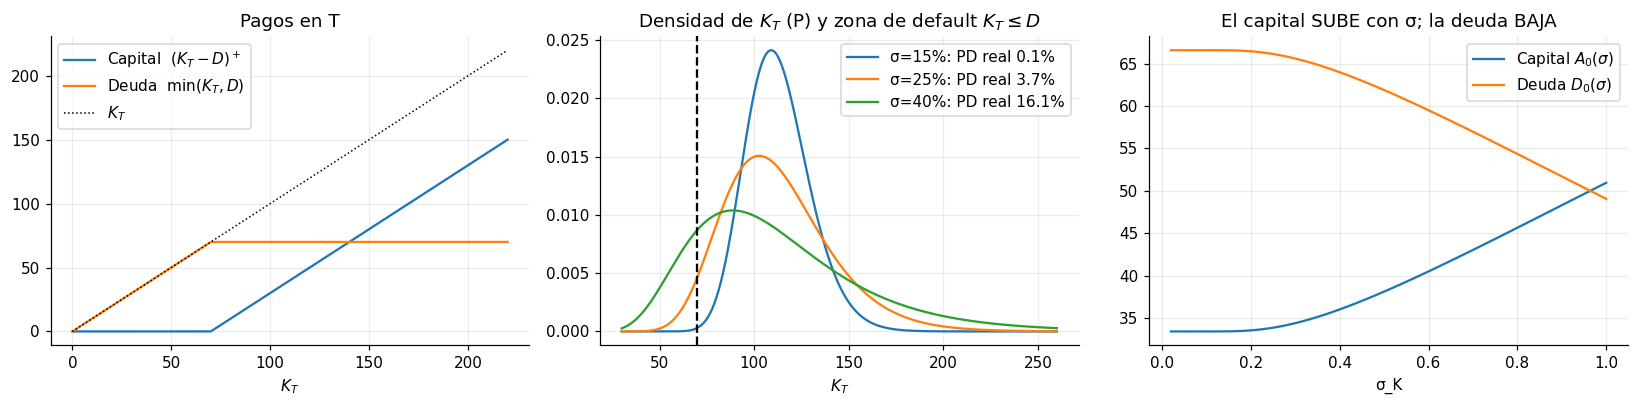

d1         1.75170
d2         1.50170
A         33.85646
Dm        66.14354
pdq        0.06659
pdp        0.03740
lgd        0.09981
spread     0.00667
delta      0.96009
eta        2.83576
Paridad  A0 + D0 − K0 = 1.4210854715202004e-14


In [3]:
# 1. Merton directo -------------------------------------------------------
K0, D, r, T, mu = 100., 70., .05, 1., .12
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
kt = np.linspace(0, 220, 400)
ax[0].plot(kt, np.maximum(kt - D, 0), label='Capital  $(K_T-D)^+$'); ax[0].plot(kt, np.minimum(kt, D), label='Deuda  $\\min(K_T,D)$'); ax[0].plot(kt, kt, 'k:', lw=1, label='$K_T$')
ax[0].set(title='Pagos en T', xlabel='$K_T$'); ax[0].legend()
for s in (.15, .25, .40):
    m_ = merton(K0, D, r, s, T, mu); x = np.linspace(30, 260, 400); sq = s*np.sqrt(T); mp = np.log(K0) + (mu - .5*s*s)*T
    ax[1].plot(x, n_((np.log(x) - mp)/sq)/(x*sq), label=f'σ={s:.0%}: PD real {m_["pdp"]:.1%}')
ax[1].axvline(D, color='k', ls='--'); ax[1].set(title='Densidad de $K_T$ (P) y zona de default $K_T\\leq D$', xlabel='$K_T$'); ax[1].legend()
ss = np.linspace(.02, 1, 80); ax[2].plot(ss, call(K0, D, r, ss, T), label='Capital $A_0(\\sigma)$'); ax[2].plot(ss, K0 - call(K0, D, r, ss, T), label='Deuda $D_0(\\sigma)$')
ax[2].set(title='El capital SUBE con σ; la deuda BAJA', xlabel='σ_K'); ax[2].legend(); plt.tight_layout(); plt.show()
m_ = merton(K0, D, r, .25, T, mu)
print(pd.Series({k: m_[k] for k in ['d1', 'd2', 'A', 'Dm', 'pdq', 'pdp', 'lgd', 'spread', 'delta', 'eta']}).round(5).to_string())
print('Paridad  A0 + D0 − K0 =', m_['A'] + m_['Dm'] - K0)

## 2. Datos de mercado
`load_firm` obtiene precio, acciones, capital de mercado y pasivos (corto/largo plazo) de Yahoo Finance.
**Punto de default** (KMV): pasivo de corto plazo + ½ pasivo de largo plazo. Con `OFFLINE` se usa el *snapshot* de tu notebook.

MODO = LIVE | WALMEX.MX | último cierre 53.61 | acciones 17.220 mm | A0 (capital de mercado) = 923.2 mm
       monto (mm)              comentario
CP         169.72      pasivo corto plazo
LP          89.98      pasivo largo plazo
Total      259.69            pasivo total
D          214.70     D = CP + ½ LP (KMV)
A0         923.18  A0 = precio × acciones
σ_A diaria anualizada (toda la muestra) = 25.76%   (2235 rendimientos)


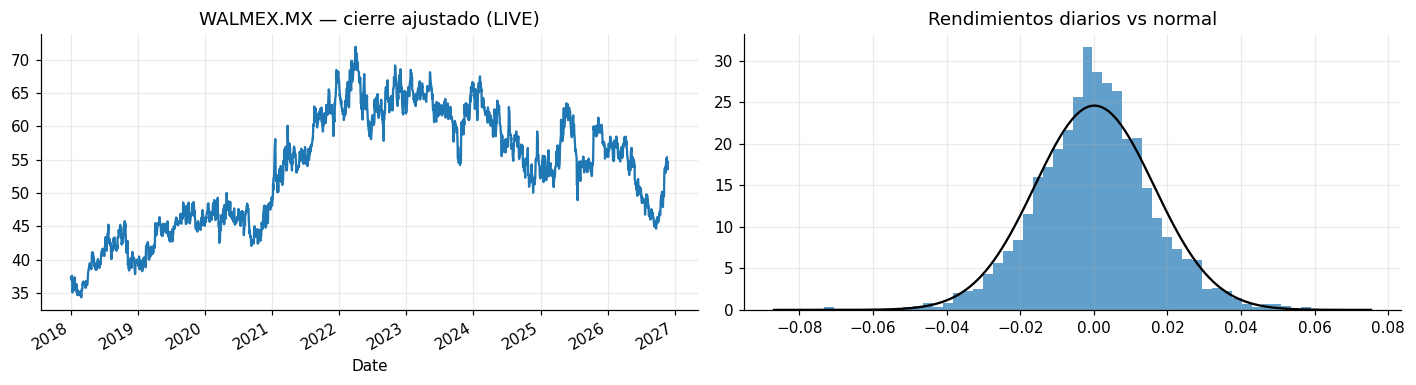

In [4]:
# 2.1 Carga de datos (yfinance) o snapshot offline ---------------------------
TICKER, INICIO, USE_YF = 'WALMEX.MX', '2018-01-01', True
SNAP = dict(ticker='WALMEX.MX', shares=17461399552., mcap=1180739829760., std=132.7085e9, tl=208.5075e9, debt=65.2797e9, last=67.62, vol=.2643, ap=96.63788e9)

def _pick(bs, *names):
    for n in names:
        if n in bs.index:
            v = bs.loc[n].dropna()
            if len(v): return float(v.iloc[0])
    return np.nan

def load_firm(tic, start=INICIO, use_yf=USE_YF, seed=133, fb=True):   # seed 133: serie simulada con σ≈26.4% (como tu snapshot) y drawdown máx. plausible (~34%)
    """→ dict(ticker, modo, px (Serie de cierres), shares, mcap, std, ltd, D_kmv, ...). Montos en unidades monetarias."""
    if use_yf:
        try:
            import yfinance as yf
            t = yf.Ticker(tic); px = t.history(start=start, auto_adjust=True)['Close'].dropna(); px.index = pd.DatetimeIndex(px.index).tz_localize(None)
            info = t.info; sh = info.get('sharesOutstanding') or getattr(t.fast_info, 'shares', None); bs = t.balance_sheet
            cl = _pick(bs, 'Current Liabilities', 'Total Current Liabilities'); tl = _pick(bs, 'Total Liabilities Net Minority Interest', 'Total Liab', 'Total Liabilities')
            if len(px) > 300 and sh and np.isfinite(cl) and np.isfinite(tl):
                return dict(ticker=tic, modo='LIVE', px=px, shares=float(sh), mcap=float(px.iloc[-1]*sh), std=cl, ltd=tl - cl, tl=tl)
            raise ValueError('datos incompletos en Yahoo')
        except Exception as e: print(f'[{tic}] yfinance falló ({type(e).__name__}: {str(e)[:70]}) → snapshot OFFLINE')
    if not fb: return None                                   # sin respaldo: el llamador decide
    rng = np.random.default_rng(seed); n = 1300; z = rng.standard_normal(n)
    lp = np.concatenate([[0], np.cumsum((.08 - .5*SNAP['vol']**2)*H + SNAP['vol']*np.sqrt(H)*z)]); px = SNAP['last']*np.exp(lp - lp[-1])
    return dict(ticker=SNAP['ticker'], modo='OFFLINE', px=pd.Series(px, index=pd.bdate_range(end='2022-06-13', periods=n + 1)), shares=SNAP['shares'],
                mcap=SNAP['mcap'], std=SNAP['std'], ltd=SNAP['tl'] - SNAP['std'], tl=SNAP['tl'])

F = load_firm(TICKER); MODO = F['modo']
F['D'] = F['std'] + .5*F['ltd']                          # punto de default KMV
ret = np.log(F['px']).diff().dropna(); F['sE'] = ret.std()*np.sqrt(252)
print(f"MODO = {MODO} | {F['ticker']} | último cierre {F['px'].iloc[-1]:.2f} | acciones {F['shares']/1e9:.3f} mm | A0 (capital de mercado) = {F['mcap']/1e9:,.1f} mm")
print(pd.DataFrame({'monto (mm)': [F['std']/1e9, F['ltd']/1e9, F['tl']/1e9, F['D']/1e9, F['mcap']/1e9], 'comentario': ['pasivo corto plazo', 'pasivo largo plazo', 'pasivo total', 'D = CP + ½ LP (KMV)', 'A0 = precio × acciones']},
                   index=['CP', 'LP', 'Total', 'D', 'A0']).round(2).to_string())
print(f"σ_A diaria anualizada (toda la muestra) = {F['sE']:.2%}   ({len(ret)} rendimientos)")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); F['px'].plot(ax=ax[0], title=f"{F['ticker']} — cierre ajustado ({MODO})"); ax[1].hist(ret, 60, density=True, alpha=.7)
x = np.linspace(ret.min(), ret.max(), 300); ax[1].plot(x, norm.pdf(x, ret.mean(), ret.std()), 'k'); ax[1].set(title='Rendimientos diarios vs normal'); plt.tight_layout(); plt.show()

## 3. Calibración KMV: de $(A_0,\sigma_A,D)$ a $(K_0,\sigma_K)$
Se resuelve $\;G_1=K\Phi(d_1)-De^{-rT}\Phi(d_2)-A_0=0,\quad G_2=\sigma K\Phi(d_1)-\sigma_AA_0=0$.
**En KMV $D$ es un dato** (el punto de default) y las incógnitas son $K_0,\sigma_K$ (tu notebook original resolvía por $D$: ver §9).

D_como       sólo CP CP + ½ LP (KMV) CP + LP (total)
D              169.7           214.7           259.7
K0              1085            1127            1170
sK            0.2193          0.2109          0.2032
eta            1.175           1.221           1.268
DD_KMV         3.847           3.838           3.829
d2             8.578           7.994           7.552
PD_Q       4.814e-18       6.534e-16       2.136e-14
PD_P       6.464e-19       9.282e-17       3.132e-15
EDF_normal 5.972e-05       6.201e-05       6.438e-05
LGD_end      0.02431         0.02499         0.02539
iters              0               0               0
metodo        newton          newton          newton

→ El punto de partida YA es la solución: con Φ(d1)≈Φ(d2)≈1 (deuda casi libre de riesgo) A0 = K0 − D e^{-rT} y σK = σA·A0/K0.

                              K0 (mm)  vs KMV  DD si K0=este y σK=σA·A0/K0
K0 calibrado (KMV)         1,127.4103  0.0000                       3.8380
EV Yahoo (enterpriseValue)   975.6

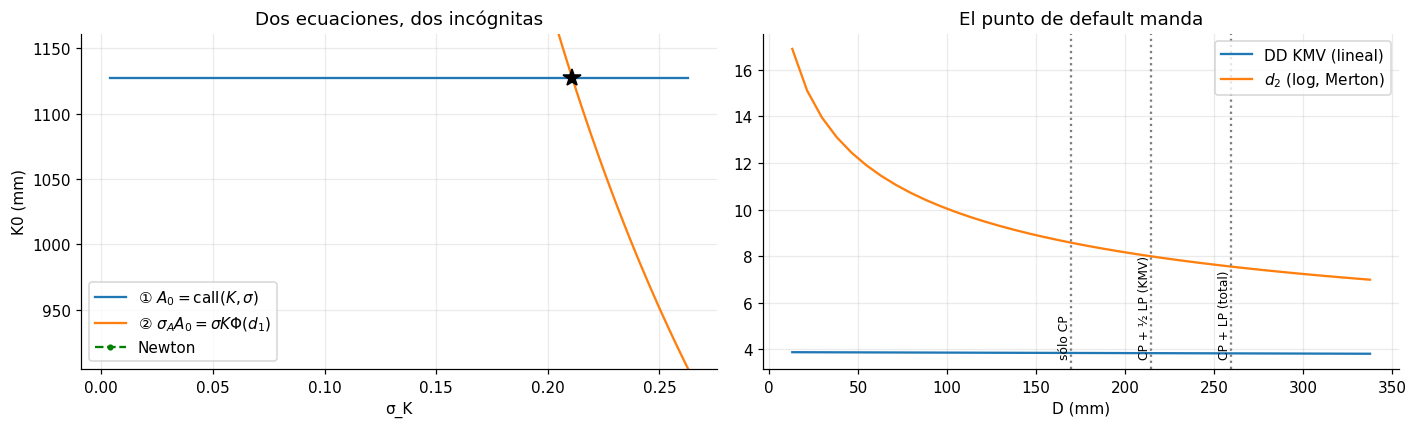

In [5]:
# 3. Calibración y sensibilidad al punto de default ---------------------------
r, T, mu, lgd = .05, 1., .10, .45
A0, sA = F['mcap'], F['sE']
defs = {'sólo CP': F['std'], 'CP + ½ LP (KMV)': F['D'], 'CP + LP (total)': F['std'] + F['ltd']}
rows = []
for nom, D_ in defs.items():
    K_, s_, tr, met = solve_kmv(A0, sA, D_, r, T); m_ = merton(K_, D_, r, s_, T, mu)
    rows.append(dict(D_como=nom, D=D_/1e9, K0=K_/1e9, sK=s_, eta=sA/s_, DD_KMV=dd_kmv(K_, D_, s_), d2=m_['d2'], PD_Q=m_['pdq'], PD_P=m_['pdp'], EDF_normal=N(-dd_kmv(K_, D_, s_)), LGD_end=m_['lgd'], iters=len(tr) - 1, metodo=met))
tab = pd.DataFrame(rows).set_index('D_como'); pd.options.display.float_format = '{:.4g}'.format; print(tab.T.to_string())
K0c, sKc, tr, _ = solve_kmv(A0, sA, F['D'], r, T)
if len(tr) == 1: print('\n→ El punto de partida YA es la solución: con Φ(d1)≈Φ(d2)≈1 (deuda casi libre de riesgo) A0 = K0 − D e^{-rT} y σK = σA·A0/K0.')

# ⚠ K0 NO se toma de Yahoo: compara el K0 calibrado con los "atajos" que la gente usa
ev = np.nan
if MODO == 'LIVE':
    try: import yfinance as yf; ev = float(yf.Ticker(F['ticker']).info.get('enterpriseValue') or np.nan)
    except Exception as e_: print('EV de Yahoo no disponible:', type(e_).__name__)
prox = {'K0 calibrado (KMV)': K0c, 'EV Yahoo (enterpriseValue)': ev, 'A0 + D  (ingenuo B–S)': A0 + F['D'], 'A0 + pasivo total': A0 + F['std'] + F['ltd']}
cmp_ = pd.DataFrame({'K0 (mm)': {k: v/1e9 for k, v in prox.items()}}); cmp_['vs KMV'] = cmp_['K0 (mm)']/(K0c/1e9) - 1
cmp_['DD si K0=este y σK=σA·A0/K0'] = [dd_kmv(v, F['D'], sA*A0/v) if np.isfinite(v) else np.nan for v in prox.values()]; cmp_.loc['K0 calibrado (KMV)', 'DD si K0=este y σK=σA·A0/K0'] = dd_kmv(K0c, F['D'], sKc)
print('\n' + cmp_.to_string(float_format='{:,.4f}'.format, na_rep='n/d'))
print('⚠️  ADVERTENCIA: K0 (valor de mercado de los ACTIVOS) no cotiza en ningún lado. Yahoo da capital de mercado (A0) y enterprise value = capitalización + deuda financiera − caja:')
print('    el EV omite pasivos operativos (p. ej. cuentas por pagar), resta caja (que es activo) y no incluye la opcionalidad de la deuda. Sirve como chequeo de cordura, NO como K0.')
print('    Tomar K0 = EV obliga además a inventar σK; eso es lo que hacía el notebook original (K0=EV, A0/2, resolver por D) y por eso fsolve no convergía.')
if MODO != 'LIVE': print('    (modo OFFLINE: el EV de Yahoo no está disponible; se muestran sólo los atajos A0+D y A0+pasivo total.)')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sx = np.linspace(.004, sA*1.02, 120); B_ = F['D']*np.exp(-r*T)
K1 = invert(np.full(len(sx), A0), F['D'], r, sx, T)                  # ① K(σ): bisección vectorizada (brentq falla por redondeo si D≪A0)
K2 = bis(lambda k: sx*k*N(d12(k, F['D'], r, sx, T)[0]) - sA*A0, sA*A0/sx, sA*A0/sx*1e6, log=True)   # ② K(σ)
ax[0].plot(sx, K1/1e9, label='① $A_0=\\mathrm{call}(K,\\sigma)$'); ax[0].plot(sx, K2/1e9, label='② $\\sigma_AA_0=\\sigma K\\Phi(d_1)$'); ax[0].plot(*zip(*[(s, k/1e9) for k, s in tr]), 'o--', ms=3, color='g', label='Newton')
ax[0].plot(sKc, K0c/1e9, 'k*', ms=12); ax[0].set(ylim=(A0/1e9*.98, (A0 + B_)/1e9*1.03), xlabel='σ_K', ylabel='K0 (mm)', title='Dos ecuaciones, dos incógnitas'); ax[0].legend()
Dg = np.linspace(.05, 1.3, 40)*(F['std'] + F['ltd']); res = [(lambda s: (dd_kmv(s[0], d, s[1]), d12(s[0], d, r, s[1], T)[1]))(solve_kmv(A0, sA, d, r, T)[:2]) for d in Dg]
ax[1].plot(Dg/1e9, [x[0] for x in res], label='DD KMV (lineal)'); ax[1].plot(Dg/1e9, [x[1] for x in res], label='$d_2$ (log, Merton)')
for nom, d_ in defs.items(): ax[1].axvline(d_/1e9, color='gray', ls=':'); ax[1].text(d_/1e9, .03, nom, rotation=90, fontsize=8, transform=ax[1].get_xaxis_transform(), va='bottom', ha='right')
ax[1].set(xlabel='D (mm)', title='El punto de default manda'); ax[1].legend(); plt.tight_layout(); plt.show()

## 3b. Merton a fondo con WALMEX: teoría, verificación e interpretación

### Supuestos del modelo (Merton, 1974)
1. Los **activos** siguen un movimiento browniano geométrico bajo $\mathbb P$: $\;dK_t=\mu K_t\,dt+\sigma_K K_t\,dW_t$ (σ constante, sin saltos).
2. La empresa tiene **un solo pasivo**: un bono cupón-cero con valor nominal $D$ que vence en $T$. No hay dividendos ni otras deudas.
3. El **default sólo puede ocurrir en $T$**: si $K_T<D$, los acreedores se quedan con los activos; si $K_T\ge D$, se les paga $D$ y los accionistas se quedan con el resto.
4. Mercado sin fricciones, tasa libre de riesgo $r$ constante ⇒ existe una medida neutral al riesgo $\mathbb Q$ bajo la cual $\mu\to r$.

### Resultados (todo se sigue de Black–Scholes)
* **Pagos:** capital $A_T=(K_T-D)^+$ (call sobre los activos) y deuda $D_T=\min(K_T,D)=D-(D-K_T)^+$ (bono libre de riesgo menos una put que los acreedores *le venden* a los accionistas).
* **Valuación:** $\;A_0=K_0\Phi(d_1)-De^{-rT}\Phi(d_2)$, $\;D_0=K_0-A_0=De^{-rT}\Phi(d_2)+K_0\Phi(-d_1)$, con
 $d_1=\dfrac{\ln(K_0/D)+(r+\sigma_K^2/2)T}{\sigma_K\sqrt T},\;d_2=d_1-\sigma_K\sqrt T$.
* **PD neutral:** $\mathbb Q(K_T\le D)=\Phi(-d_2)$. **PD real:** misma fórmula con $\mu$: $\;\mathrm{PD}_{\mathbb P}=\Phi(-\mathrm{DD}_M)$, $\;\mathrm{DD}_M=\dfrac{\ln(K_0/D)+(\mu-\sigma_K^2/2)T}{\sigma_K\sqrt T}=d_2+\lambda\sqrt T$,
 donde $\lambda=(\mu-r)/\sigma_K$ es el **precio de mercado del riesgo** ⇒ $\;\mathrm{PD}_{\mathbb P}=\Phi(-d_2-\lambda\sqrt T)<\mathrm{PD}_{\mathbb Q}$ si $\mu>r$.
* **LGD endógena** (no se supone, sale del modelo): $\;\mathbb E_{\mathbb Q}[K_T\mid K_T\le D]=\dfrac{K_0e^{rT}\Phi(-d_1)}{\Phi(-d_2)}\Rightarrow \mathrm{LGD}=1-\dfrac{K_0e^{rT}\Phi(-d_1)}{D\,\Phi(-d_2)}$.
* **Spread:** como $D_0e^{rT}/D=1-\mathrm{PD}_{\mathbb Q}\cdot\mathrm{LGD}$ (pérdida esperada neutral), $\;s=-\dfrac1T\ln\!\big(1-\mathrm{PD}_{\mathbb Q}\,\mathrm{LGD}\big)\approx\dfrac{\mathrm{PD}_{\mathbb Q}\,\mathrm{LGD}}{T}$.
* **Puente con KMV:** $\Delta=\Phi(d_1)=\partial A/\partial K$ ⇒ por el lema de Itô $\;\sigma_A A_0=\Delta\,\sigma_K K_0$, es decir $\;\sigma_A=\eta\,\sigma_K$ con $\eta=K_0\Phi(d_1)/A_0$ (elasticidad del capital). Esa es la 2ª ecuación del sistema de la sección 3.
* **Vega:** $\partial A/\partial\sigma_K=K_0\varphi(d_1)\sqrt T>0$ y $\partial D_0/\partial\sigma_K=-K_0\varphi(d_1)\sqrt T<0$ ⇒ los accionistas ganan si el riesgo sube (*sustitución de activos*) y los acreedores pierden.

### Límites que hay que tener presentes (y que verás en los datos de WALMEX)
* **Difusión pura ⇒ PD(T→0)→0 y spread(T→0)→0** para cualquier empresa solvente (el «problema del corto plazo»; por eso existen saltos, barrera y KMV empírico: sección 5 y 6).
* Con apalancamiento bajo ($D/K_0\approx13\%$) las PD salen del orden de $10^{-21}$: **Merton sirve para ordenar empresas y medir sensibilidades, no para fijar una PD absoluta de grado de inversión.** Por eso Basilea impone un piso de 0.03 %.
* $K_0$ y $\sigma_K$ **no se observan**: dependen de cómo se calibren (sección 3–4) y de la definición de $D$.

In [6]:
# 3b.1 Identidades de Merton verificadas con WALMEX. Sobre WALMEX "hoy" las PD son ~1e-21 y el redondeo domina,
# así que cada identidad se verifica también en una WALMEX apalancada (D = 75% de K0), donde los números sí se ven.
def ident(K, D_, s_, mu_):
    d1, d2 = d12(K, D_, r, s_, T); m_ = merton(K, D_, r, s_, T, mu_); lam = (mu_ - r)/s_; EL = m_['pdq']*m_['lgd']
    spread_num = -np.log((K - call(K, D_, r, s_, T))/D_)/T - r                       # definición numérica: D0 = K0 − A0
    return [('PD real  =  Φ(−d2 − λ√T)', m_['pdp'], N(-d2 - lam*np.sqrt(T))),
            ('spread  =  −ln(1 − PD_Q·LGD)/T', spread_num, -np.log1p(-EL)/T),
            ('D0  =  D e^(−rT)Φ(d2) + K0 Φ(−d1)', K - call(K, D_, r, s_, T), D_*np.exp(-r*T)*N(d2) + K*N(-d1))]
rows = [dict(caso=c, identidad=n, izquierda=a, derecha=b, err_rel=abs(a - b)/abs(b)) for c, D_ in (('D/K0 = 75% (apalancada)', .75*K0c), ) for n, a, b in ident(K0c, D_, sKc, mu)]
print(pd.DataFrame(rows).to_string(index=False, float_format='{:.6g}'.format))
m0 = merton(K0c, F['D'], r, sKc, T, mu); lam = (mu - r)/sKc
print(f"\nWALMEX hoy (D/K0 = {F['D']/K0c:.1%}):  PD_Q = {m0['pdq']:.2e}   PD_P = {m0['pdp']:.2e}   PD_P/PD_Q = {m0['pdp']/m0['pdq']:.3f}   (λ = {lam:.3f}, μ = {mu:.0%}, r = {r:.0%})")
print(f"  spread = {m0['spread']*1e4:.2e} pb   LGD endógena = {m0['lgd']:.2%}   Δ = {m0['delta']:.6f}   η = {m0['eta']:.4f}   |  calibración: σA = η·σK → {m0['eta']*sKc:.4%} vs σA de mercado {F['sE']:.4%}")
print(f"  paridad A0 + D0 − K0 = {m0['A'] + m0['Dm'] - K0c:.1e}  (en pesos)")

                   caso                         identidad  izquierda    derecha     err_rel
D/K0 = 75% (apalancada)          PD real  =  Φ(−d2 − λ√T)  0.0415924  0.0415924           0
D/K0 = 75% (apalancada)    spread  =  −ln(1 − PD_Q·LGD)/T 0.00578458 0.00578458 9.44646e-15
D/K0 = 75% (apalancada) D0  =  D e^(−rT)Φ(d2) + K0 Φ(−d1) 7.9968e+11 7.9968e+11           0

WALMEX hoy (D/K0 = 19.0%):  PD_Q = 6.53e-16   PD_P = 9.28e-17   PD_P/PD_Q = 0.142   (λ = 0.237, μ = 10%, r = 5%)
  spread = 1.63e-13 pb   LGD endógena = 2.50%   Δ = 1.000000   η = 1.2212   |  calibración: σA = η·σK → 25.7594% vs σA de mercado 25.7594%
  paridad A0 + D0 − K0 = -2.4e-04  (en pesos)


MODO = LIVE
                                  caída del capital  caída implícita de activos  PD neutral a 1 año tras ese choque
peor caída pico–valle del precio             0.3791                      0.3105                           2.308e-10
peor caída a 12 meses                        0.2192                      0.1795                           8.577e-13

Para llegar al punto de default los ACTIVOS deben caer 81.0% (ln = 1.66):  4.5× la peor caída histórica implícita  |  7.9 desviaciones estándar anuales de σK.


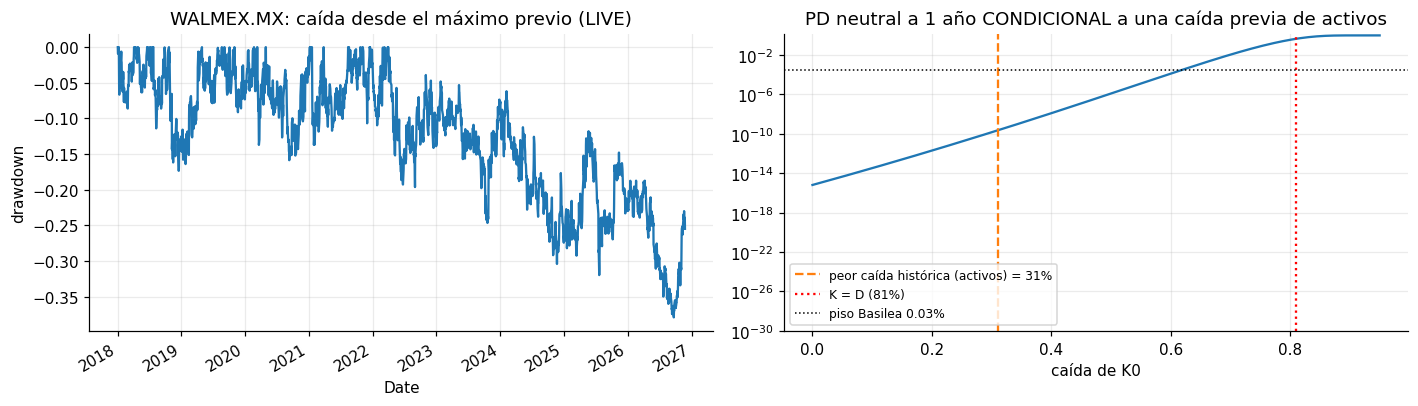

In [7]:
# 3b.2 ¿Qué tan lejos está WALMEX del default en unidades HISTÓRICAS? (usa la serie F['px']: LIVE si hay red, simulada en OFFLINE)
px_ = F['px']; lr_ = np.log(px_).diff().dropna(); dd_ser = px_/px_.cummax() - 1;
mdd = -dd_ser.min(); w1y = 1 - np.exp(lr_.rolling(252).sum().min())
A0_, D_, K0_, s_ = F['mcap'], F['D'], K0c, sKc
def asset_drop(eq_drop):                       # caída de ACTIVOS compatible con una caída del CAPITAL: el capital es una call ⇒ cae η veces más
    return 1 - invert(np.array([A0_*(1 - eq_drop)]), D_, r, s_, T)[0]/K0_
pd_after = lambda h: N(-d12(K0_*(1 - h), D_, r, s_, T)[1])
hist = pd.DataFrame({k: {'caída del capital': v, 'caída implícita de activos': asset_drop(v), 'PD neutral a 1 año tras ese choque': pd_after(asset_drop(v))}
                     for k, v in {'peor caída pico–valle del precio': mdd, 'peor caída a 12 meses': w1y}.items()}).T
print(f'MODO = {MODO}'); print(hist.to_string(float_format='{:.4g}'.format))
need = 1 - D_/K0_; h_worst = asset_drop(mdd)
print(f'\nPara llegar al punto de default los ACTIVOS deben caer {need:.1%} (ln = {np.log(K0_/D_):.2f}):  {np.log(K0_/D_)/-np.log(1 - h_worst):.1f}× la peor caída histórica implícita  |  {np.log(K0_/D_)/(s_*np.sqrt(T)):.1f} desviaciones estándar anuales de σK.')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); dd_ser.plot(ax=ax[0]); ax[0].set(title=f"{F['ticker']}: caída desde el máximo previo ({MODO})", ylabel='drawdown')
hh = np.linspace(0, .95, 200); ax[1].semilogy(hh, np.maximum(pd_after(hh), 1e-40)); ax[1].axvline(h_worst, color='C1', ls='--', label=f'peor caída histórica (activos) = {h_worst:.0%}'); ax[1].axvline(need, color='r', ls=':', label=f'K = D ({need:.0%})')
ax[1].axhline(3e-4, color='k', ls=':', lw=1, label='piso Basilea 0.03%'); ax[1].set(title='PD neutral a 1 año CONDICIONAL a una caída previa de activos', xlabel='caída de K0', ylim=(1e-30, 1.5)); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

In [8]:
# 3b.3 Colas y clusters de volatilidad: ¿el supuesto lognormal subestima la probabilidad de caídas grandes de los ACTIVOS?
from scipy.stats import skew, kurtosis
n_est = min(len(F['px']), 756); A_s_ = (F['px'].iloc[-n_est:]*F['shares']).values; km_ = kmv_iter(A_s_, F['D'], r, T); rK = np.diff(np.log(km_['K']))
print(f"MODO = {MODO} | K̂ diario: σ = {rK.std()*np.sqrt(252):.2%}  asimetría = {skew(rK):.2f}  exceso de curtosis = {kurtosis(rK):.2f}   (lognormal: 0 y 0)")
rng = np.random.default_rng(0); B, bl, nb = 200_000, 21, 12                      # 12 bloques de 21 días = 252: el bootstrap por bloques conserva los clusters de volatilidad
cs = np.concatenate([[0], np.cumsum(rK)]); i0 = rng.integers(0, len(rK) - bl + 1, (B, nb)); ann = (cs[i0 + bl] - cs[i0]).sum(1)
thr = [.10, .20, .30, .40]; pb = np.array([(ann <= np.log(1 - h)).mean() for h in thr]); pn = np.array([norm.cdf((np.log(1 - h) - ann.mean())/ann.std()) for h in thr])
print(pd.DataFrame({'P(activos caen ≥ h en 1a) bootstrap': pb, 'lognormal (misma μ, σ)': pn, 'razón': np.where(pn > 0, pb/np.maximum(pn, 1e-300), np.nan)}, index=[f'h = {h:.0%}' for h in thr]).to_string(float_format='{:.3g}'.format))
if MODO == 'OFFLINE': print('(OFFLINE: la serie es un GBM simulado ⇒ no hay colas gordas por construcción; con yfinance la razón suele ser > 1 en las colas.)')

MODO = LIVE | K̂ diario: σ = 21.11%  asimetría = -0.02  exceso de curtosis = 1.87   (lognormal: 0 y 0)
         P(activos caen ≥ h en 1a) bootstrap  lognormal (misma μ, σ)  razón
h = 10%                                0.366                    0.36   1.02
h = 20%                                0.132                   0.132  0.998
h = 30%                               0.0212                   0.024  0.883
h = 40%                             0.000995                 0.00149  0.668


### Ejercicios (con los números de WALMEX; las soluciones están en la celda siguiente)
1. **Identidad del spread.** Demuestra que $D_0e^{rT}/D=1-\mathrm{PD}_{\mathbb Q}\cdot\mathrm{LGD}$ usando $D_0=De^{-rT}\Phi(d_2)+K_0\Phi(-d_1)$ y la fórmula de LGD. Verifícalo con 3b.1.
2. **Prima de riesgo.** En la WALMEX apalancada ($D/K_0=75\%$) calcula $\mathrm{PD}_{\mathbb P}/\mathrm{PD}_{\mathbb Q}$ y explícalo con $\lambda\sqrt T$. ¿Qué $\mu$ haría que la PD real fuera la mitad de la neutral?
3. **Piso de Basilea.** ¿Qué deuda $D^\*$ (y qué $D^\*/K_0$) hace que la PD neutral de WALMEX sea **0.03 %**? ¿Cuántas veces es la deuda real? ¿Qué te dice sobre usar Merton para una PD absoluta?
4. **¿Qué mueve más la PD?** Sube y baja 20 % cada insumo ($K_0,D,\sigma_K,r,T$) y mide el cambio en $\log_{10}\mathrm{PD}_{\mathbb Q}$. Ordena de mayor a menor y explica el signo de cada uno con $\partial d_2/\partial(\cdot)$.
5. **σ implícita del mercado de bonos.** Dado un spread observado de un bono de WALMEX a 5 años, ¿qué $\sigma_K$ lo reproduce? ¿Cómo se compara con la $\sigma_K$ calibrada de acciones? ¿Qué implica sobre la PD? *(El spread de la celda es un SUPUESTO: reemplázalo por el de tu proveedor de precios, p. ej. Valmer/PIP o Bloomberg.)*
6. **Lectura de 3b.2.** ¿Cuántas veces la peor caída histórica de activos hace falta para llegar a $K=D$? ¿Es creíble una PD de $10^{-21}$ con ese margen?

E2  PD_P/PD_Q = 0.617   λ√T = 0.237   μ que da PD_P = ½PD_Q: 12.04%
E3  D* = 562 mm  (D*/K0 = 49.9%) = 2.6× la deuda real de 215 mm → con σK=21.1%, para que Merton dé el piso de Basilea WALMEX tendría que deber 2.6× lo que debe.
E4  Δ log10 PD_Q al mover cada insumo ±20%:
    −20%  +20%
σK -8.11  4.43
D  -3.97  2.89
K0  3.49 -3.21
T   -3.4  2.27
r   0.17 -0.17
E5  spread supuesto 60 pb (5a) → σK implícita = 45.9%  (2.2× la calibrada de acciones, 21.1%);  PD_Q(5a) con esa σ = 8.91%   (con la σ calibrada: spread = 1.39e-02 pb)


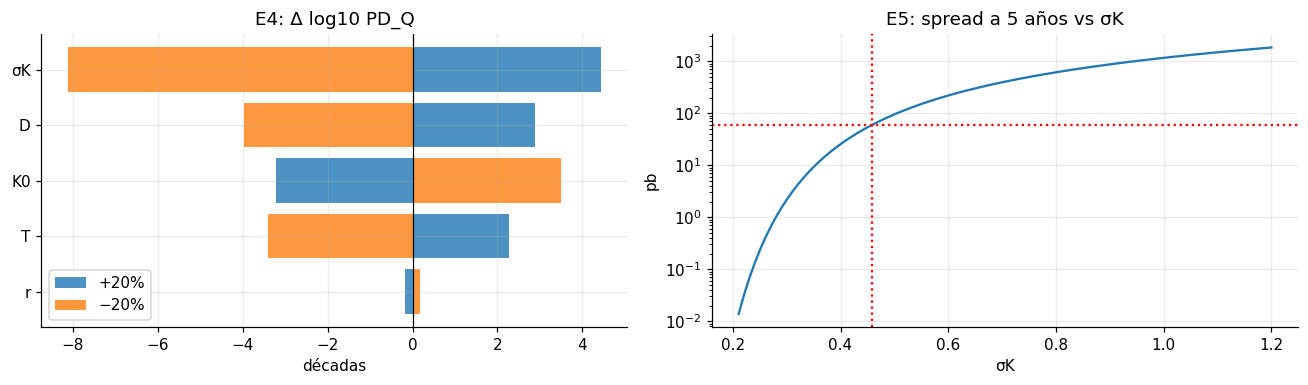

In [9]:
# 3b.4 SOLUCIONES ------------------------------------------------------------------------------------------------
SPREAD_MERCADO_PB = 60.          # ← SUPUESTO ilustrativo: pon aquí el spread real (pb) de un bono de WALMEX a 5 años
# E1: verificada numéricamente en 3b.1 (errores relativos ≈ 1e-13). Álgebra: D0 e^{rT}/D = Φ(d2) + K0 e^{rT}Φ(−d1)/D = 1 − [Φ(−d2) − K0 e^{rT}Φ(−d1)/D] = 1 − PD·LGD.
# E2   (bis asume f creciente: aquí f = ½PD_Q − PD_P(μ) es creciente en μ)
Ks, Ds_, ss_ = K0c, .75*K0c, sKc; m2 = merton(Ks, Ds_, r, ss_, T, mu); lam = (mu - r)/ss_
mu_half = float(bis(lambda mu_: -(N(-d12(Ks, Ds_, r, ss_, T)[1] - (mu_ - r)/ss_*np.sqrt(T))) + .5*m2['pdq'], r, r + 5.))     # decreciente en μ ⇒ cambio de signo; bis asume creciente → usamos −f
print(f"E2  PD_P/PD_Q = {m2['pdp']/m2['pdq']:.3f}   λ√T = {lam*np.sqrt(T):.3f}   μ que da PD_P = ½PD_Q: {mu_half:.2%}")
# E3
D_b = float(bis(lambda D_: N(-d12(K0c, D_, r, sKc, T)[1]) - 3e-4, F['D'], 50*K0c))
print(f"E3  D* = {D_b/1e9:,.0f} mm  (D*/K0 = {D_b/K0c:.1%}) = {D_b/F['D']:.1f}× la deuda real de {F['D']/1e9:,.0f} mm → con σK={sKc:.1%}, para que Merton dé el piso de Basilea WALMEX tendría que deber {D_b/F['D']:.1f}× lo que debe.")
# E4: tornado ±20%
lp = lambda K, D_, s_, r_, T_: np.log10(max(float(N(-d12(K, D_, r_, s_, T_)[1])), 1e-300)); b0 = dict(K=K0c, D=F['D'], s=sKc, r=r, T=T)
tor = {n: [lp(**{**{'K': b0['K'], 'D_': b0['D'], 's_': b0['s'], 'r_': b0['r'], 'T_': b0['T']}, {'K': 'K', 'D': 'D_', 's': 's_', 'r': 'r_', 'T': 'T_'}[n]: b0[n]*f}) - lp(b0['K'], b0['D'], b0['s'], b0['r'], b0['T']) for f in (.8, 1.2)] for n in b0}
tor = pd.DataFrame(tor, index=['−20%', '+20%']).T.rename(index={'K': 'K0', 'D': 'D', 's': 'σK', 'r': 'r', 'T': 'T'}); tor = tor.reindex(tor.abs().max(1).sort_values(ascending=False).index); print('E4  Δ log10 PD_Q al mover cada insumo ±20%:'); print(tor.round(2).to_string())
# E5: σ implícita de un spread a 5 años (vectorizable: spread creciente en σ)
spr5 = lambda s_: -np.log1p(-(N(-d12(K0c, F['D'], r, s_, 5.)[1]) - K0c*np.exp(r*5.)*N(-d12(K0c, F['D'], r, s_, 5.)[0])/F['D']))/5.*1e4
s_imp = float(bis(lambda s_: spr5(s_) - SPREAD_MERCADO_PB, sKc, 3.)); pq5 = N(-d12(K0c, F['D'], r, s_imp, 5.)[1])
print(f"E5  spread supuesto {SPREAD_MERCADO_PB:.0f} pb (5a) → σK implícita = {s_imp:.1%}  ({s_imp/sKc:.1f}× la calibrada de acciones, {sKc:.1%});  PD_Q(5a) con esa σ = {pq5:.2%}   (con la σ calibrada: spread = {spr5(sKc):.2e} pb)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6)); ax[0].barh(tor.index[::-1], tor['+20%'][::-1], label='+20%', alpha=.8); ax[0].barh(tor.index[::-1], tor['−20%'][::-1], label='−20%', alpha=.8); ax[0].axvline(0, color='k', lw=.8); ax[0].set(title='E4: Δ log10 PD_Q', xlabel='décadas'); ax[0].legend()
sg_ = np.linspace(sKc, 1.2, 100); ax[1].plot(sg_, [spr5(x) for x in sg_]); ax[1].axhline(SPREAD_MERCADO_PB, color='r', ls=':'); ax[1].axvline(s_imp, color='r', ls=':'); ax[1].set(title='E5: spread a 5 años vs σK', xlabel='σK', ylabel='pb', yscale='log'); plt.tight_layout(); plt.show()

### Cómo leer los resultados de 3b (conclusiones que no dependen del modo de datos)
* **Las identidades se cumplen al nivel del redondeo** (error relativo ≲1e-13 en 3b.1): el modelo es internamente consistente; las discrepancias con el mercado vienen de los *supuestos*, no de la fórmula.
* **El margen de WALMEX es enorme**: 3b.2 te dice cuánto tendrían que caer los activos para llegar a $D$ y cuántas veces es eso la peor caída histórica (usa la columna «caída implícita de activos»: el capital cae $\eta$ veces más rápido que los activos). La PD de Merton es ≈0 porque el modelo lo dice, no porque «la empresa no pueda quebrar».
* **Lo informativo no es el nivel de la PD sino su sensibilidad** (tornado de E4): con apalancamiento bajo, $\sigma_K$ domina por mucho (≈11 décadas al bajarla 20 %); $T$, $D$ y $K_0$ pesan parecido entre sí (3–5 décadas) y $r$ prácticamente no importa.
* **σ implícita > σ de acciones** cuando el spread de mercado es mayor que el del modelo: el mercado de crédito cobra por riesgos (saltos, liquidez, cola, prima de riesgo de crédito) que la difusión con $\sigma$ constante no captura.

## 4. Estimación con la serie de tiempo
Con sólo el último día y la $\sigma_A$ de toda la muestra, la calibración es ruidosa. **KMV iterativo** usa toda la serie: invierte Black–Scholes cada día para reconstruir $K_t$, calcula $\sigma_K$ de ese camino y repite (punto fijo). **Duan (1994)**: MLE tratando el capital como datos transformados; Duan–Gauthier–Simonato (2005) muestran que KMV es el MLE.
**Ojo:** $\hat\mu$ sale muy ruidoso (error ≈ $\sigma/\sqrt{\text{años}}$); $\sigma_K$ en cambio se estima muy bien. Por eso en la cartera se usa $\mu=r+$ prima supuesta. Primero una **prueba con verdad conocida** (simulación) y luego los datos de mercado.

                    σK      μ
verdad            0.25   0.12
① una sola σ_A  0.3765    NaN
② KMV iterativo 0.2491 0.3244
③ MLE Duan      0.2484 0.3242
④ ingenuo B–S   0.4227    NaN
|σ_KMV − σ_MLE| / σ = 0.27%  (Duan et al.: mismo punto; aquí ≈ por ddof y fin de muestra)
Iteraciones KMV: 9; σ por vuelta: [0.3711 0.258  0.2496 0.2491 0.2491 0.2491]


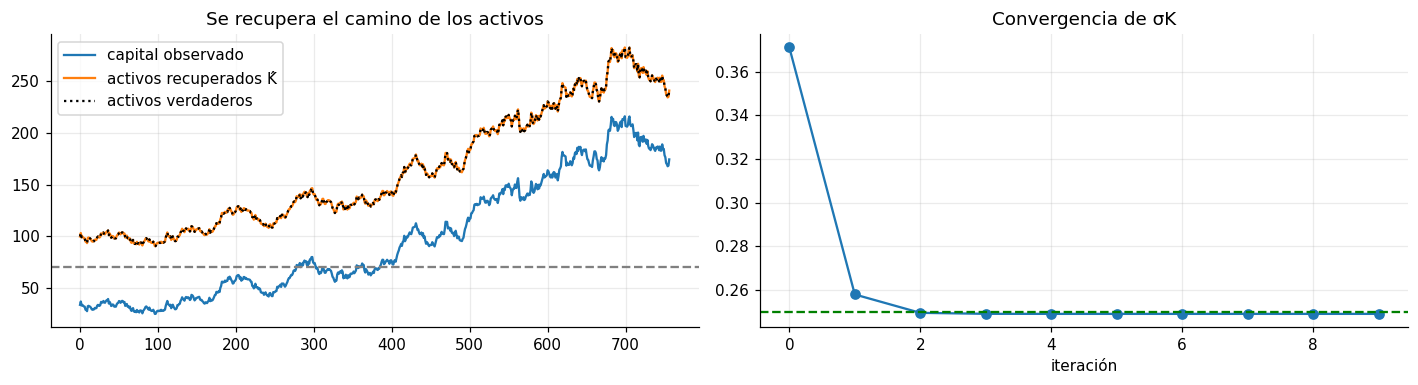

In [10]:
# 4.1 Prueba controlada: verdad conocida -----------------------------------------
Kt, At = simulate(100, 70, .05, .12, .25, 1, 756, noise=0., seed=3)
sE_ = np.diff(np.log(At)).std(ddof=1)*np.sqrt(252); uno = solve_kmv(At[-1], sE_, 70, .05, 1)
km = kmv_iter(At, 70, .05, 1); mu_m, s_m = mle_duan(At, 70, .05, 1)
bs_dd, bs_pd, bs_sV = naive_bs(At[-1], 70, sE_, np.log(At[-1]/At[-253]))
print(pd.DataFrame({'σK': [.25, uno[1], km['sK'], s_m, bs_sV], 'μ': [.12, np.nan, km['mu'], mu_m, np.nan]}, index=['verdad', '① una sola σ_A', '② KMV iterativo', '③ MLE Duan', '④ ingenuo B–S']).round(4).to_string())
print(f"|σ_KMV − σ_MLE| / σ = {abs(km['sK'] - s_m)/km['sK']:.2%}  (Duan et al.: mismo punto; aquí ≈ por ddof y fin de muestra)")
print(f"Iteraciones KMV: {len(km['trace']) - 1}; σ por vuelta: {np.round(km['trace'][:6], 4)}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); ax[0].plot(At, label='capital observado'); ax[0].plot(km['K'], label='activos recuperados K̂'); ax[0].plot(Kt, 'k:', label='activos verdaderos'); ax[0].axhline(70, color='gray', ls='--'); ax[0].legend(); ax[0].set(title='Se recupera el camino de los activos')
ax[1].plot(km['trace'], 'o-'); ax[1].axhline(.25, color='g', ls='--'); ax[1].set(title='Convergencia de σK', xlabel='iteración'); plt.tight_layout(); plt.show()

                   sesgo  desv.est.   RMSE
① una sola σ_A     0.037     0.0801 0.0879
② KMV iterativo  -0.0002      0.009 0.0089
④ B–S ingenuo σV  0.1522     0.0566 0.1623


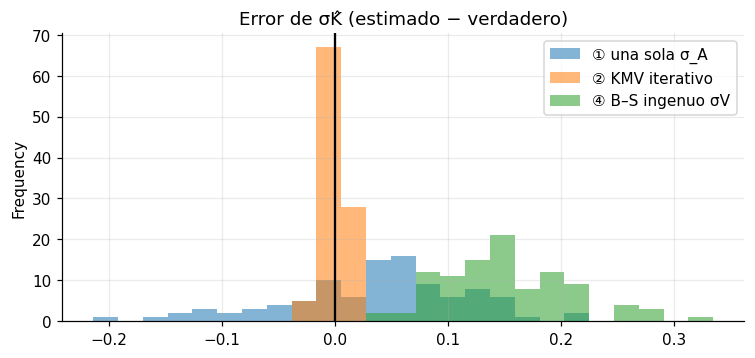

In [11]:
# 4.2 ¿Quién se equivoca más? 100 repeticiones (n = 504 días) ---------------------
rep = {'① una sola σ_A': [], '② KMV iterativo': [], '④ B–S ingenuo σV': []}
for i in range(100):
    _, A_ = simulate(100, 70, .05, .12, .25, 1, 504, seed=1000 + i); sE = np.diff(np.log(A_)).std(ddof=1)*np.sqrt(252)
    rep['① una sola σ_A'].append(solve_kmv(A_[-1], sE, 70, .05, 1)[1] - .25); rep['② KMV iterativo'].append(kmv_iter(A_, 70, .05, 1)['sK'] - .25); rep['④ B–S ingenuo σV'].append(naive_bs(A_[-1], 70, sE, 0, 1)[2] - .25)
R_ = pd.DataFrame(rep); print(pd.DataFrame({'sesgo': R_.mean(), 'desv.est.': R_.std(), 'RMSE': np.sqrt((R_**2).mean())}).round(4).to_string())
R_.plot.hist(bins=25, alpha=.55, figsize=(8, 3.4), title='Error de σK̂ (estimado − verdadero)'); plt.axvline(0, color='k'); plt.show()

MODO = LIVE, n = 756 días
                           σK  K0 (mm)  DD KMV  d2 (μ=r)
① una σ_A (último día) 0.2097     1127   3.861     8.042
② KMV iterativo        0.2113     1127   3.832     7.981
③ MLE Duan             0.2111     1127   3.834     7.986
④ ingenuo B–S          0.2293     1138   3.538     7.377


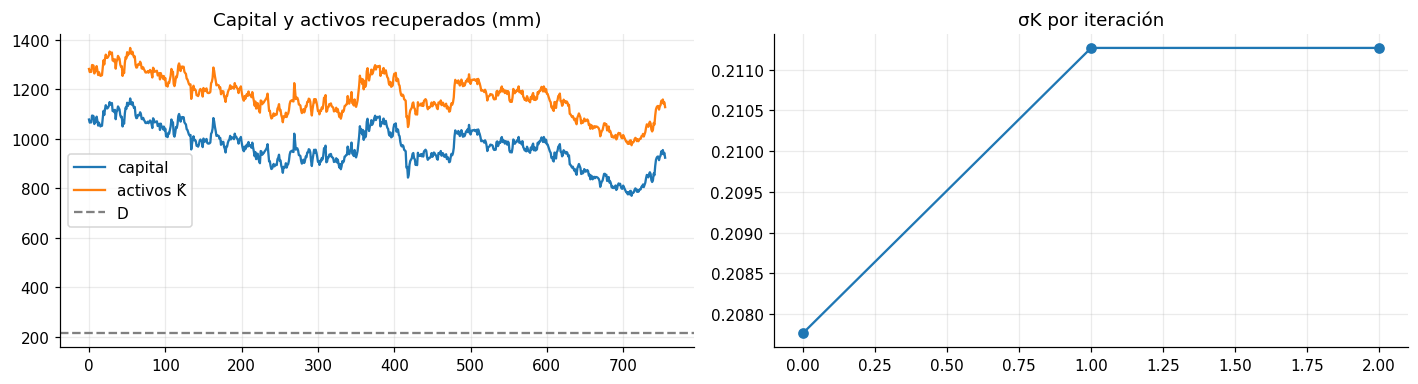

In [12]:
# 4.3 Datos de mercado: KMV iterativo, MLE e ingenuo con la serie real (o simulada OFFLINE) --------
n_est = min(len(F['px']), 756); A_s = (F['px'].iloc[-n_est:]*F['shares']).values; D_ = F['D']
km = kmv_iter(A_s, D_, r, T); mu_m, s_m = mle_duan(A_s, D_, r, T, x0=(km['mu'], np.log(km['sK']))); rp = np.log(A_s[-1]/A_s[-min(253, n_est)])
bs_dd, bs_pd, bs_sV = naive_bs(A_s[-1], D_, km['sE'], rp, T); one = solve_kmv(A_s[-1], km['sE'], D_, r, T)
out = pd.DataFrame({'σK': [one[1], km['sK'], s_m, bs_sV], 'K0 (mm)': [one[0]/1e9, km['K'][-1]/1e9, invert(A_s[-1:], D_, r, s_m, T)[0]/1e9, (A_s[-1] + D_)/1e9]},
                   index=['① una σ_A (último día)', '② KMV iterativo', '③ MLE Duan', '④ ingenuo B–S'])
out['DD KMV'] = [dd_kmv(a*1e9, D_, b) for a, b in zip(out['K0 (mm)'], out['σK'])]; out['d2 (μ=r)'] = [d12(a*1e9, D_, r, b, T)[1] for a, b in zip(out['K0 (mm)'], out['σK'])]
print(f"MODO = {MODO}, n = {n_est} días"); print(out.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); ax[0].plot(A_s/1e9, label='capital'); ax[0].plot(km['K']/1e9, label='activos K̂'); ax[0].axhline(D_/1e9, color='gray', ls='--', label='D'); ax[0].legend(); ax[0].set(title='Capital y activos recuperados (mm)')
ax[1].plot(km['trace'], 'o-'); ax[1].set(title='σK por iteración'); plt.tight_layout(); plt.show()

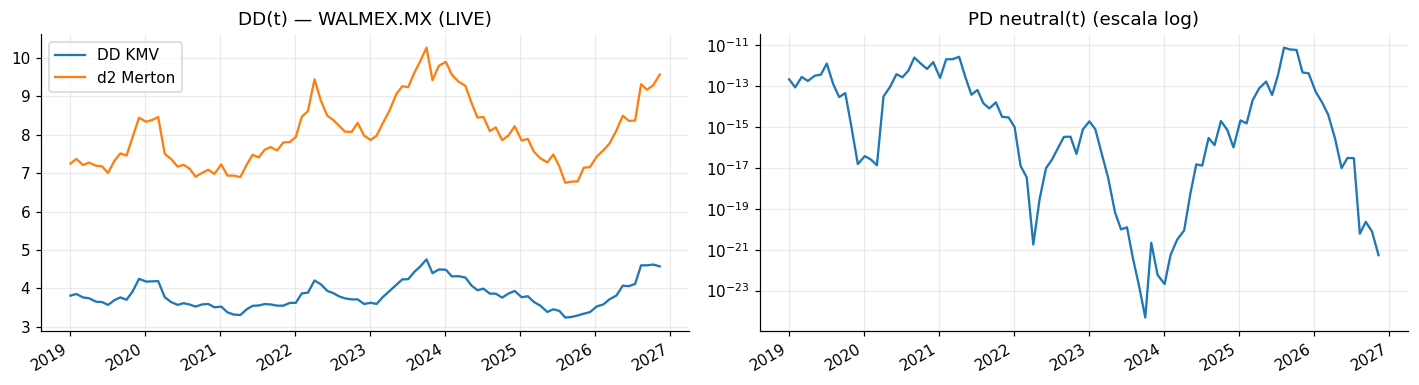

            DD KMV  d2 Merton  PD neutral
2026-07-13   4.112      8.367   2.958e-17
2026-08-11   4.597      9.316   6.048e-21
2026-09-09   4.598      9.174    2.29e-20
2026-10-09   4.618      9.289   7.817e-21
2026-11-10    4.57      9.569   5.388e-22


In [13]:
# 4.4 DD(t): ventana móvil de 1 año, actualizada cada mes ----------------------
px = F['px']; fechas, dds, pds, dls = [], [], [], []
for j in range(252, len(px), 21):
    w = px.iloc[j - 252:j + 1]; sE_w = np.log(w).diff().std()*np.sqrt(252); A_w = w.iloc[-1]*F['shares']
    K_, s_, _, _ = solve_kmv(A_w, sE_w, F['D'], r, T); fechas.append(w.index[-1]); dds.append(dd_kmv(K_, F['D'], s_)); pds.append(merton(K_, F['D'], r, s_, T, r)['pdq']); dls.append(d12(K_, F['D'], r, s_, T)[1])
dd_t = pd.DataFrame({'DD KMV': dds, 'd2 Merton': dls, 'PD neutral': pds}, index=fechas)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); dd_t[['DD KMV', 'd2 Merton']].plot(ax=ax[0], title=f"DD(t) — {F['ticker']} ({MODO})"); dd_t['PD neutral'].clip(lower=1e-300).plot(ax=ax[1], logy=True, title='PD neutral(t) (escala log)'); plt.tight_layout(); plt.show()
print(dd_t.tail(5).to_string())

## 5. Extensiones
* **Black–Cox (1976):** el default ocurre la **primera vez** que $K_t\le B$. $\;P(\min_{t\le T}K_t\le B)=\Phi\!\big(\tfrac{b-mT}{\sigma\sqrt T}\big)+e^{2mb/\sigma^2}\Phi\!\big(\tfrac{b+mT}{\sigma\sqrt T}\big)$, $b=\ln(B/K_0)$, $m=\mu-\sigma^2/2$.
* **Saltos (Merton 1976):** $\ln K$ tiene saltos lognormales; con la **misma varianza total** se corrige la PD de corto plazo (el «problema del corto plazo» de la difusión pura).
* Se validan ambas fórmulas con Monte Carlo antes de usarlas.

Black–Cox  MC = 0.0888   fórmula = 0.0889
Saltos     MC = 0.1142   fórmula = 0.1142


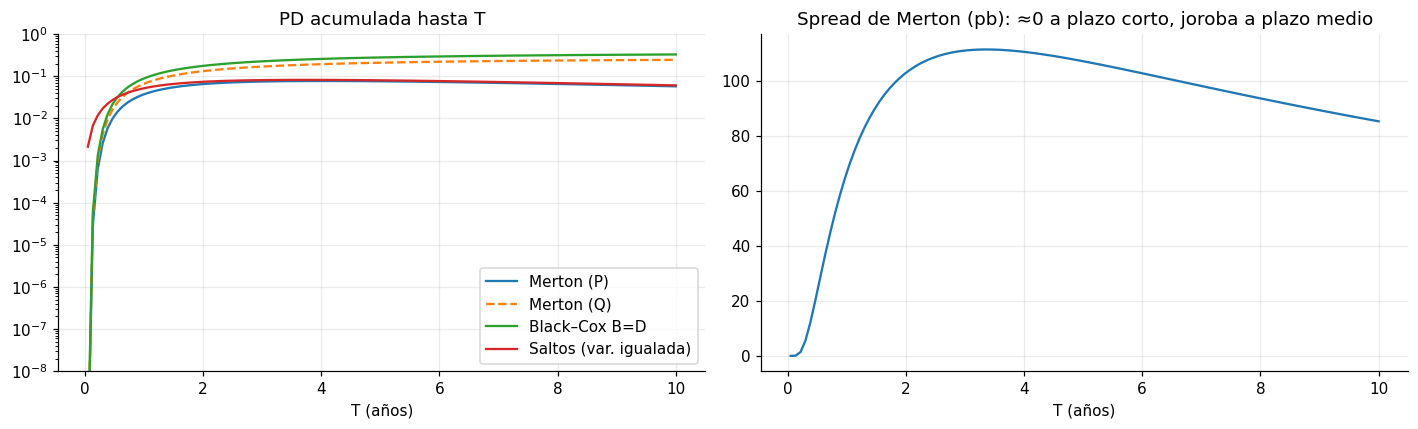

     Merton P  Black–Cox  Saltos
3 m    0.122%     0.257%  1.394%
1 a    3.740%     8.894%  5.206%
3 a    7.513%    22.667%  8.115%
5 a    7.609%    28.014%  8.024%


In [14]:
# 5. Barrera y saltos: validación MC + curvas por plazo ----------------------------
rng = np.random.default_rng(5); K0, D, mu, s, T1 = 100., 70., .12, .25, 1.
# (a) Black–Cox por MC con corrección de puente browniano
M, n = 200000, 1000; h = T1/n; lk = np.full(M, np.log(K0)); b = np.log(D); hit = np.zeros(M, bool)
for _ in range(n):
    new = lk + (mu - .5*s*s)*h + s*np.sqrt(h)*rng.standard_normal(M); pc = np.where((lk > b) & (new > b), np.exp(-2*(lk - b)*(new - b)/(s*s*h)), 1.0)
    hit |= rng.random(M) < pc; lk = new
print(f'Black–Cox  MC = {hit.mean():.4f}   fórmula = {black_cox_pd(K0, D, mu, s, T1):.4f}')
# (b) saltos por MC
lam, mj, dj = 2., -.08, .15; k = np.exp(mj + .5*dj**2) - 1; Nj = rng.poisson(lam*T1, M)
lkT = np.log(K0) + (mu - .5*s*s - lam*k)*T1 + s*np.sqrt(T1)*rng.standard_normal(M) + Nj*mj + np.sqrt(Nj)*dj*rng.standard_normal(M)
print(f'Saltos     MC = {(lkT <= b).mean():.4f}   fórmula = {jump_pd(K0, D, mu, s, T1, lam, mj, dj)[0]:.4f}')

# (c) curvas por plazo con misma varianza total: σ_dif² = σ² − λ(μJ²+δJ²)
Ts = np.linspace(.05, 10, 120); lam, mj, dj = 1.5, -.12, .12; sd_ = np.sqrt(s*s - lam*(mj*mj + dj*dj))
pdm = np.array([merton(K0, D, .05, s, t, mu)['pdp'] for t in Ts]); pdq = np.array([merton(K0, D, .05, s, t, mu)['pdq'] for t in Ts])
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); ax[0].semilogy(Ts, pdm, label='Merton (P)'); ax[0].semilogy(Ts, pdq, '--', label='Merton (Q)'); ax[0].semilogy(Ts, black_cox_pd(K0, D, mu, s, Ts), label='Black–Cox B=D'); ax[0].semilogy(Ts, jump_pd(K0, D, mu, sd_, Ts, lam, mj, dj), label='Saltos (var. igualada)')
ax[0].set(ylim=(1e-8, 1), xlabel='T (años)', title='PD acumulada hasta T'); ax[0].legend()
sp = np.array([merton(K0, D, .05, s, t)['spread'] for t in Ts])*1e4; ax[1].plot(Ts, sp); ax[1].set(title='Spread de Merton (pb): ≈0 a plazo corto, joroba a plazo medio', xlabel='T (años)'); plt.tight_layout(); plt.show()
print(pd.DataFrame({'Merton P': [merton(K0, D, .05, s, t, mu)['pdp'] for t in (.25, 1, 3, 5)], 'Black–Cox': black_cox_pd(K0, D, mu, s, np.array([.25, 1, 3, 5])), 'Saltos': jump_pd(K0, D, mu, sd_, np.array([.25, 1, 3, 5]), lam, mj, dj)}, index=['3 m', '1 a', '3 a', '5 a']).to_string(float_format='{:.3%}'.format))

## 6. Del DD a la EDF empírica (la segunda opción del PDF)
KMV no usa $\Phi(-\mathrm{DD})$: arma una base de empresas con su DD, deja pasar un año y calcula **EDF(DD) = quebrados / empresas con ese DD**. Aquí se simula esa base con **colas $t_\nu$** e **incertidumbre de la volatilidad**: en un mundo normal Merton funciona; en uno realista la EDF a DD≈3–4 es mucho mayor que la de Merton en logaritmos.

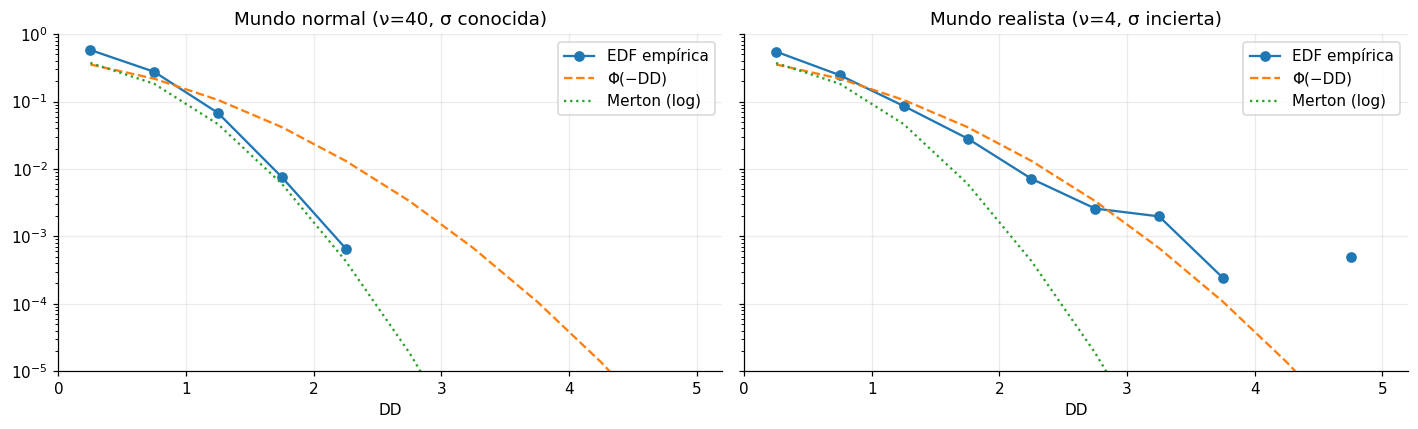

            n  quiebras   phi_DD  merton_log  EDF_emp
2.0–2.5  9078        65 1.32e-02    4.31e-04 7.16e-03
2.5–3.0  7352        19 3.34e-03    1.86e-05 2.58e-03
3.0–3.5  5554        11 6.70e-04    4.81e-07 1.98e-03
3.5–4.0  4125         1 1.08e-04    8.43e-09 2.42e-04
4.0–4.5  2932         0 1.36e-05    9.83e-11 0.00e+00
4.5–5.0  2007         1 1.35e-06    5.55e-13 4.98e-04


In [15]:
# 6. EDF empírica vectorizada ---------------------------------------------------------
def edf_empirica(nf=60000, nu=4, vv=.4, mu=.06, seed=11, bw=.5, nb=16):
    rng = np.random.default_rng(seed); L = np.clip(rng.beta(2, 3, nf), .02, .97); s0 = .25*np.exp(.45*rng.standard_normal(nf)); dd = (1 - L)/s0
    sr = s0*np.exp(vv*rng.standard_normal(nf) - vv**2/2); lk = np.zeros(nf); hit = np.zeros(nf, bool); sc = 1. if nu >= 40 else np.sqrt((nu - 2)/nu)
    for _ in range(12):                                   # 12 observaciones mensuales
        e = rng.standard_normal(nf) if nu >= 40 else rng.standard_t(nu, nf)*sc
        lk += (mu - .5*sr**2)/12 + sr/np.sqrt(12)*e; hit |= lk <= np.log(L)
    bi = np.floor(dd/bw).astype(int); ok = bi < nb
    df = pd.DataFrame(dict(b=bi[ok], d=hit[ok], nm=N(-dd[ok]), pm=N(-dd_mer(1, L[ok], s0[ok], 1, mu)))).groupby('b').agg(n=('d', 'size'), quiebras=('d', 'sum'), phi_DD=('nm', 'mean'), merton_log=('pm', 'mean'))
    df['EDF_emp'] = df.quiebras/df.n; df.index = [f'{i*bw:.1f}–{(i + 1)*bw:.1f}' for i in df.index]; return df
mundos = {'Mundo normal (ν=40, σ conocida)': edf_empirica(nu=40, vv=0), 'Mundo realista (ν=4, σ incierta)': edf_empirica(nu=4, vv=.4)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, (nom, df) in zip(ax, mundos.items()):
    x = np.arange(len(df))*.5 + .25; e = df.EDF_emp.where(df.quiebras > 0); a.semilogy(x, e, 'o-', label='EDF empírica'); a.semilogy(x, df.phi_DD, '--', label='Φ(−DD)'); a.semilogy(x, df.merton_log, ':', label='Merton (log)')
    a.set(title=nom, xlabel='DD', ylim=(1e-5, 1), xlim=(0, 5.2)); a.legend()
plt.tight_layout(); plt.show(); print(mundos['Mundo realista (ν=4, σ incierta)'].iloc[4:10].to_string(float_format='{:.2e}'.format))

## 7. Cartera: correlación de activos, Gaussian copula y Vasicek
Para cada empresa: PD real de Merton $\to$ umbral $\Phi^{-1}(\mathrm{PD}_i)$. La **correlación de activos** se estima con los rendimientos de $\hat K_t$ (activos recuperados por KMV) y se simula la pérdida con una *Gaussian copula*; se compara con la aproximación de **un factor** (Vasicek / Basilea IRB, el «modelo de valor crítico de un factor» del PDF).

[GFNORTEO.MX] yfinance falló (ValueError: datos incompletos en Yahoo) → snapshot OFFLINE
[ELEKTRA.MX] yfinance falló (ValueError: datos incompletos en Yahoo) → snapshot OFFLINE
MODO cartera = LIVE | 6 empresas | 504 días
               D_K     sK  mu_hat    DD  PD  LGD_end
ticker                                              
WALMEX.MX   0.1904  0.213  0.0374 3.801   0   0.0255
AMXB.MX     0.4025 0.1321  0.1506 4.525   0   0.0174
CEMEXCPO.MX 0.0408  0.315  0.3086 3.046   0   0.0295
GMEXICOB.MX 0.0065  0.356     0.4 2.791   0   0.0243
FEMSAUBD.MX 0.4165 0.1236   0.125 4.719   0   0.0158
BIMBOA.MX   0.3911 0.1663  0.0703 3.661   0   0.0262

Correlación de activos promedio (observada) ρ̄ = 0.242


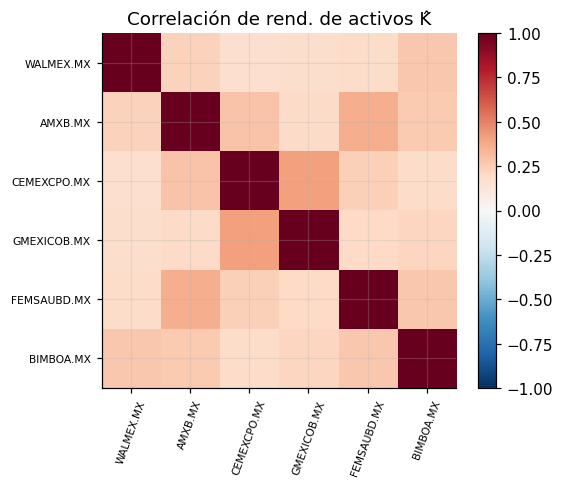

In [16]:
# 7.1 Universo de empresas (LIVE si hay red; si no, universo simulado con un factor común) ------------
TICKERS = ['WALMEX.MX', 'AMXB.MX', 'GFNORTEO.MX', 'CEMEXCPO.MX', 'GMEXICOB.MX', 'FEMSAUBD.MX', 'BIMBOA.MX', 'ELEKTRA.MX']
def universo(tickers=TICKERS, use_yf=USE_YF, nf=10):
    firmas, fallos = [], 0
    for t in (tickers if use_yf else []):
        f = load_firm(t, fb=False); firmas += [f] if f else []; fallos = 0 if f else fallos + 1
        if fallos >= 3: break                                  # sin red / Yahoo caído: no insistir
    if len(firmas) >= 4:                                       # los bancos (GFNORTE…) no tienen CP/LP: se descartan solos
        px = pd.concat({f['ticker']: f['px'] for f in firmas}, axis=1).dropna().iloc[-504:]; return firmas, px, 'LIVE'
    rng = np.random.default_rng(21); n = 504; zc = rng.standard_normal(n); rows = []; cols = {}
    for i in range(nf):                                       # universo sintético: 1 factor común (ρ_f=.35), σ y apalancamiento heterogéneos
        s = rng.uniform(.18, .45); L = rng.uniform(.40, .80); rho_f = .35
        z = np.sqrt(rho_f)*zc + np.sqrt(1 - rho_f)*rng.standard_normal(n); K = 100*np.exp(np.concatenate([[0], np.cumsum((.07 - .5*s*s)*H + s*np.sqrt(H)*z)]))
        D_ = L*K[-1]; cols[f'Firma{i + 1}'] = call(K, D_, .05, s, 1.); rows.append(dict(ticker=f'Firma{i + 1}', modo='OFFLINE', shares=1., std=.7*D_, ltd=.6*D_, tl=1.3*D_, mcap=cols[f'Firma{i + 1}'][-1]))
    return rows, pd.DataFrame(cols, index=pd.bdate_range(end='2022-06-13', periods=n + 1)), 'OFFLINE'
firmas, PX, MODO7 = universo(); print('MODO cartera =', MODO7, '|', len(firmas), 'empresas |', len(PX), 'días')
PRIMA = .04      # μ = r + prima supuesta: el μ̂ de la serie tiene error ≈ σ/√años (≈15–25 pp con 2–3 años), inservible para PD
res = []
for f in firmas:
    A_ = (PX[f['ticker']]*f['shares']).values; D_ = f['std'] + .5*f['ltd']; km = kmv_iter(A_, D_, .05, 1.); K_ = km['K'][-1]
    m_ = merton(K_, D_, .05, km['sK'], 1., .05 + PRIMA); res.append(dict(ticker=f['ticker'], D_K=D_/K_, sK=km['sK'], mu_hat=km['mu'], DD=dd_kmv(K_, D_, km['sK']), PD=max(m_['pdp'], 1e-6), LGD_end=m_['lgd'], dK=np.diff(np.log(km['K']))))
U = pd.DataFrame(res).set_index('ticker'); print(U.drop(columns='dK').round(4).to_string())
Cm = np.corrcoef(np.vstack(U.dK.values)); rho_bar = (Cm.sum() - len(Cm))/(len(Cm)*(len(Cm) - 1)); print(f'\nCorrelación de activos promedio (observada) ρ̄ = {rho_bar:.3f}')
plt.figure(figsize=(5.2, 4.2)); plt.imshow(Cm, cmap='RdBu_r', vmin=-1, vmax=1); plt.xticks(range(len(U)), U.index, rotation=70, fontsize=7); plt.yticks(range(len(U)), U.index, fontsize=7); plt.colorbar(); plt.title('Correlación de rend. de activos K̂'); plt.show()

                             EL      σ  VaR 99.0%  ES 99.0%
independiente (ρ=0)           0 0.0014          0         0
un factor, ρ̄=0.24            0  0.001          0         0
copula con matriz observada   0  0.002          0         0
VaR asintótico (ASRF, ρ̄) = 0.0000  (sin granularidad: con 6 empresas el MC es la referencia)


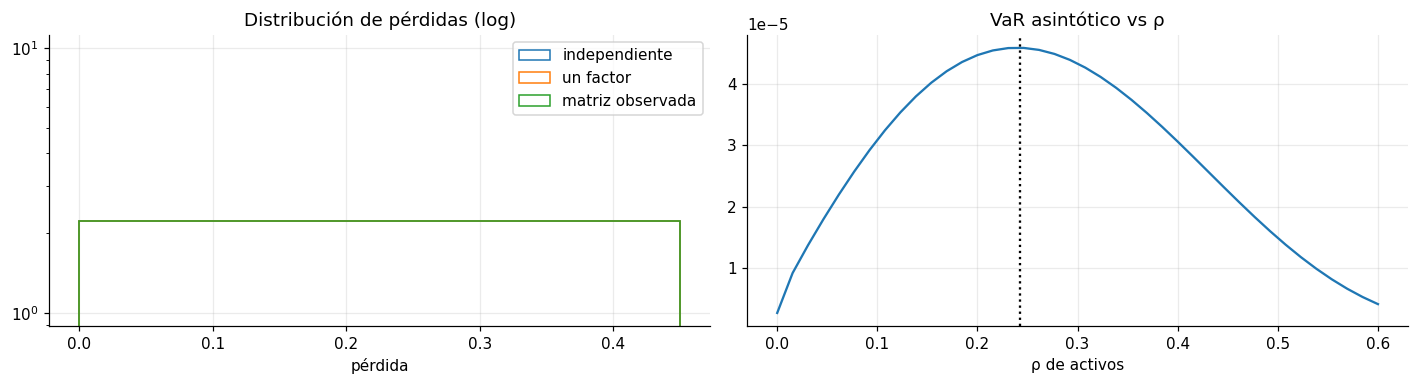


ρ_EDF (fórmula del PDF) con EDF_X=2%, EDF_Y=3%:
ρ_activos=0.1   0.0166
ρ_activos=0.3   0.0707
ρ_activos=0.5   0.1619
ρ_activos=0.7   0.3092


In [17]:
# 7.2 Pérdida de la cartera: copula con matriz observada vs un factor con ρ̄ ----------------------------
rng = np.random.default_rng(3); M = 200000; n = len(U); pdv = U.PD.values; th = norm.ppf(pdv); ead = np.ones(n); lg = .45; al = .99
Lc = np.linalg.cholesky(Cm + 1e-8*np.eye(n)); Z = rng.standard_normal((M, n)) @ Lc.T; loss_c = ((Z <= th)*ead*lg).sum(1)
z0 = rng.standard_normal((M, 1)); X1 = np.sqrt(max(rho_bar, 0))*z0 + np.sqrt(1 - max(rho_bar, 0))*rng.standard_normal((M, n)); loss_1 = ((X1 <= th)*ead*lg).sum(1)
ind = (rng.standard_normal((M, n)) <= th); loss_0 = (ind*ead*lg).sum(1)
q = lambda x: np.quantile(x, al); es = lambda x: x[x >= q(x)].mean()
asrf = sum(lg*ead[i]*N((th[i] + np.sqrt(rho_bar)*norm.ppf(al))/np.sqrt(1 - rho_bar)) for i in range(n))
print(pd.DataFrame({'EL': [x.mean() for x in (loss_0, loss_1, loss_c)], 'σ': [x.std() for x in (loss_0, loss_1, loss_c)], f'VaR {al:.1%}': [q(x) for x in (loss_0, loss_1, loss_c)], f'ES {al:.1%}': [es(x) for x in (loss_0, loss_1, loss_c)]},
                   index=['independiente (ρ=0)', f'un factor, ρ̄={rho_bar:.2f}', 'copula con matriz observada']).round(4).to_string()); print(f'VaR asintótico (ASRF, ρ̄) = {asrf:.4f}  (sin granularidad: con {n} empresas el MC es la referencia)')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); b_ = np.arange(0, loss_c.max() + .45, .45*lg/.45)
for x, nom in ((loss_0, 'independiente'), (loss_1, 'un factor'), (loss_c, 'matriz observada')): ax[0].hist(x, b_, histtype='step', density=True, label=nom)
ax[0].set(yscale='log', title='Distribución de pérdidas (log)', xlabel='pérdida'); ax[0].legend()
rr = np.linspace(0, .6, 40); ax[1].plot(rr, [sum(lg*N((th[i] + np.sqrt(x)*norm.ppf(al))/np.sqrt(1 - x)) for i in range(n)) for x in rr]); ax[1].axvline(rho_bar, color='k', ls=':'); ax[1].set(title='VaR asintótico vs ρ', xlabel='ρ de activos'); plt.tight_layout(); plt.show()
p1, p2 = .02, .03; print('\nρ_EDF (fórmula del PDF) con EDF_X=2%, EDF_Y=3%:'); print(pd.Series({f'ρ_activos={ra}': rho_edf(p1, p2, ra)[0] for ra in (.1, .3, .5, .7)}).round(4).to_string())

## 8. Ejercicios
1. **Punto de default.** En §3 cambia `defs` y mide cuánto se mueve la DD de WALMEX al pasar de «sólo CP» a «CP + LP». ¿Por qué *no* se mueve la DD lineal y sí $d_2$? (Pista: $\ln(K_0/D)$ vs $(K_0-D)/K_0$ cuando $K_0\gg D$.)
2. **Una empresa en problemas.** Usa $A_0=5$, $D=100$, $\sigma_A=100\%$ en `solve_kmv`. ¿Converge Newton? ¿Qué $\eta$ resulta? Dibuja la sección 3 con estos datos.
3. **Ruido de precio.** En §4.1 llama `simulate(..., noise=.02)`. ¿Qué pasa con $\hat\sigma_K$ en KMV vs MLE? ¿Qué supuesto del modelo se rompe?
4. **Horizonte.** Recalcula la tabla de §3 con `T=3` y `T=0.25`. ¿La PD sube o baja? ¿Depende del apalancamiento?
5. **Colas.** En §6 prueba $\nu\in\{3,4,6,10,40\}$ y `vv`$\in\{0,.2,.4,.6\}$. ¿A partir de qué combinación la EDF empírica supera a $\Phi(-\mathrm{DD})$ en DD=3–4?
6. **Correlación.** En §7.2 reemplaza `Cm` por una matriz con $\rho=.1$ y otra con $\rho=.5$ (todas iguales fuera de la diagonal). ¿Cómo cambian VaR y ES? ¿Y $\rho_{EDF}$?
7. **Para pensar.** Un banco con apalancamiento 10× ¿es buen candidato para Merton? ¿Qué es «deuda» y «punto de default» ahí?
8. **Mercado mexicano.** KMV advierte que en acciones poco líquidas la volatilidad se subestima. Compara $\sigma_A$ de dos emisoras líquidas y una poco líquida (cambia `TICKERS`).

## 9. Errores del notebook original y referencias
**Notebook `Merton_KMV_py.ipynb` (todo verificado en su salida):**
* **PD = 1 − Φ(d₁)** (celdas 8–9): usa $(r+\tfrac12\sigma^2)$; la PD de Merton es $\Phi(-d_2)=1-\Phi(d_2)$. Subestima la PD (daba 1.4e-8).
* **Se fija $K_0$ = *enterprise value*** de Yahoo y se **divide $A_0$ entre 2** (`A_0=A_0*1/2`) para que `fsolve` converja; luego se resuelve $(D,\sigma_K)$: es el problema inverso. En KMV $D$ es el dato y las incógnitas son $(K_0,\sigma_K)$.
* **Celda 14:** `fsolve` terminó con «The iteration is not making good progress» (`fvec`≈1e12) y $D=7D_0$: $K_0$ y $\sigma_K$ quedan en el valor inicial, pero se calcula DI y EDF = 0.78, que no significan nada.
* $D_0$ = «Total Liab» (208.5 mm) incluye ≈96.6 mm de cuentas por pagar (pasivo operativo); KMV usa CP + ½ LP.
* $\sigma_A$ calculada con **toda** la historia (no condicional); y la PD no usa $\mu$ (PD real).
* `yfinance 0.1.70` y etiquetas viejas del balance («Total Liab»): con versiones nuevas cambian.

**PDF (cap. 3):** el ejemplo KMV dice $\mathrm{DI}=(12.51-10)/(12.51\cdot0.0961)=2.82$; la cuenta da **2.09** ($d_2=2.80$). Reproducimos $K_0=12.51$, $\sigma_K=9.61\%$ (verificación al inicio). La fórmula «VaR$=\tilde D\,\Phi^{-1}(1-\alpha)L$», tal como aparece, mezcla un cuantil normal con una pérdida de Bernoulli.

**Referencias:** Merton (1974) *J. Finance* 29(2) · Black & Cox (1976) *J. Finance* 31(2) · Merton (1976) *JFE* 3 · Leland & Toft (1996) *J. Finance* 51(3) · Crosbie & Bohn (2003) *Modeling Default Risk*, Moody's KMV · Duan (1994) *Math. Finance* 4(2) · Duan, Gauthier & Simonato (2005) *On the equivalence of the KMV and ML methods*, GERAD G-2005-06 · Bharath & Shumway (2008) *Rev. Financial Studies* 21(3) · Vasicek (2002) *Risk* 15(12).
Moody's KMV: *default point ≈ pasivos de corto plazo + ½ de largo plazo* (CreditEdge Quick Reference).